
# **Banana leaves YOLOV8 Training**



In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!nvidia-smi

Sat Apr 19 14:43:47 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   60C    P8             13W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
import os


In [4]:
# Pip install method (recommended)

!pip install ultralytics==8.0.196

from IPython import display
display.clear_output()

import ultralytics
ultralytics.checks()

Ultralytics YOLOv8.0.196 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 41.0/112.6 GB disk)


In [5]:
!pip install ultralytics

In [6]:
from ultralytics import YOLO

from IPython.display import display, Image

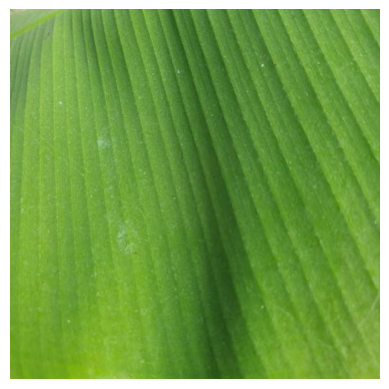

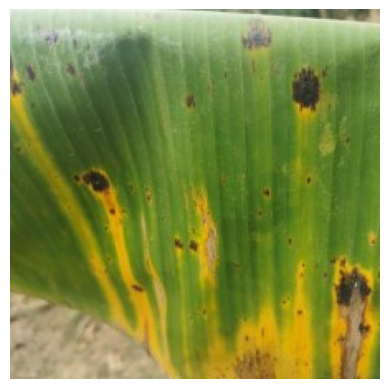

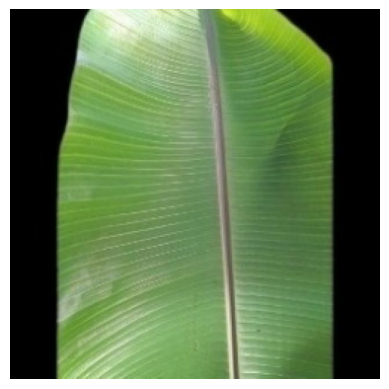

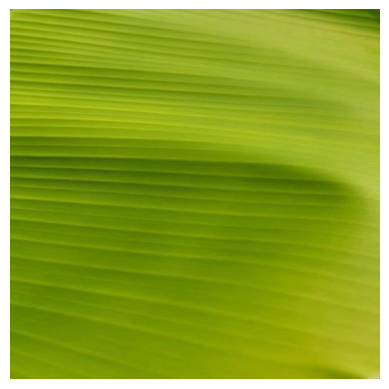

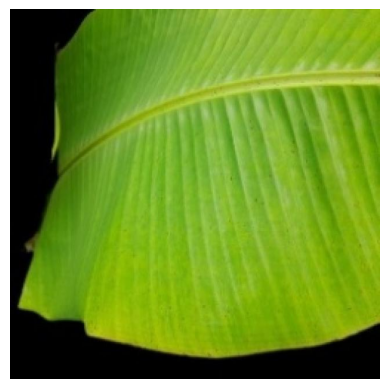

In [7]:
import os
import random
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

def display_random_images(folder_path, num_images=5):
    # Check if the folder exists
    if not os.path.exists(folder_path):
        print(f"The folder {folder_path} does not exist.")
        return

    # List all files in the folder
    files = os.listdir(folder_path)

    # Filter out only image files
    image_files = [f for f in files if f.endswith(('jpg', 'jpeg', 'png', 'gif', 'bmp'))]

    # Check if there are enough image files
    if len(image_files) < num_images:
        print(f"There are not enough image files in {folder_path}.")
        return

    # Select random images
    random_images = random.sample(image_files, num_images)

    # Display each random image
    for image_file in random_images:
        image_path = os.path.join(folder_path, image_file)
        try:
            img = mpimg.imread(image_path)
            plt.imshow(img)
            plt.axis('off')
            plt.show()
        except Exception as e:
            print(f"Failed to display image {image_path}: {e}")

# Specify the folder containing images
folder_path = "/content/drive/MyDrive/Final_Project/Banana/train/images"

# Call the function to display 5 random images from the folder
display_random_images(folder_path)


In [8]:
import os

def count_images_in_folder(folder_path):
    # Check if the folder exists
    if not os.path.exists(folder_path):
        print(f"The folder {folder_path} does not exist.")
        return 0

    # List all files in the folder
    files = os.listdir(folder_path)

    # Filter out only image files
    image_files = [f for f in files if f.endswith(('jpg', 'jpeg', 'png', 'gif', 'bmp'))]

    # Return the count of image files
    return len(image_files)

# Specify paths to train, test, and val folders
train_folder = "/content/drive/MyDrive/Final_Project/Banana/train/images"
test_folder = "/content/drive/MyDrive/Final_Project/Banana/test/images"
val_folder = "/content/drive/MyDrive/Final_Project/Banana/valid/images"

# Count images in each folder
train_count = count_images_in_folder(train_folder)
test_count = count_images_in_folder(test_folder)
val_count = count_images_in_folder(val_folder)

# Print the counts
print(f"Number of instances in trainning data: {train_count}")
print(f"Number of instances in testing data: {test_count}")
print(f"Number of instances in validation data: {val_count}")


Number of instances in trainning data: 2430
Number of instances in testing data: 348
Number of instances in validation data: 692


In [9]:
%cd /content/drive/MyDrive/Final_Project/Banana/Banana_Results
!yolo task=detect mode=predict model=yolov8n.pt conf=0.25 source='https://media.roboflow.com/notebooks/examples/dog.jpeg' save=True

/content/drive/MyDrive/Final_Project/Banana/Banana_Results
Traceback (most recent call last):
  File "/usr/local/bin/yolo", line 8, in <module>
    sys.exit(entrypoint())
             ^^^^^^^^^^^^
  File "/usr/local/lib/python3.11/dist-packages/ultralytics/cfg/__init__.py", line 420, in entrypoint
    model = YOLO(model, task=task)
            ^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.11/dist-packages/ultralytics/engine/model.py", line 97, in __init__
    self._load(model, task)
  File "/usr/local/lib/python3.11/dist-packages/ultralytics/engine/model.py", line 149, in _load
    self.model, self.ckpt = attempt_load_one_weight(weights)
                            ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.11/dist-packages/ultralytics/nn/tasks.py", line 628, in attempt_load_one_weight
    ckpt, weight = torch_safe_load(weight)  # load ckpt
                   ^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.11/dist-packages/ultralytics/nn/tasks.py", l

In [10]:
!pip install roboflow --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.2/85.2 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 19.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 89.4 MB/s eta 0:00:00


In [11]:
!pip install --upgrade ultralytics
!pip install --upgrade albumentations

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 978.8/978.8 kB 36.7 MB/s eta 0:00:00
  Attempting uninstall: ultralytics
    Found existing installation: ultralytics 8.0.196
    Uninstalling ultralytics-8.0.196:
      Successfully uninstalled ultralytics-8.0.196


In [12]:
%cd /content/drive/MyDrive/Final_Project/Banana/Banana_Results

!yolo task=detect mode=train model=yolov8n.pt data="/content/drive/MyDrive/Final_Project/Banana/data.yaml" epochs=50 imgsz=800 plots=True


/content/drive/MyDrive/Final_Project/Banana/Banana_Results
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.3.111 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: task=detect, mode=train, model=yolov8n.pt, data=/content/drive/MyDrive/Final_Project/Banana/data.yaml, epochs=50, time=None, patience=100, batch=16, imgsz=800, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=train2, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.

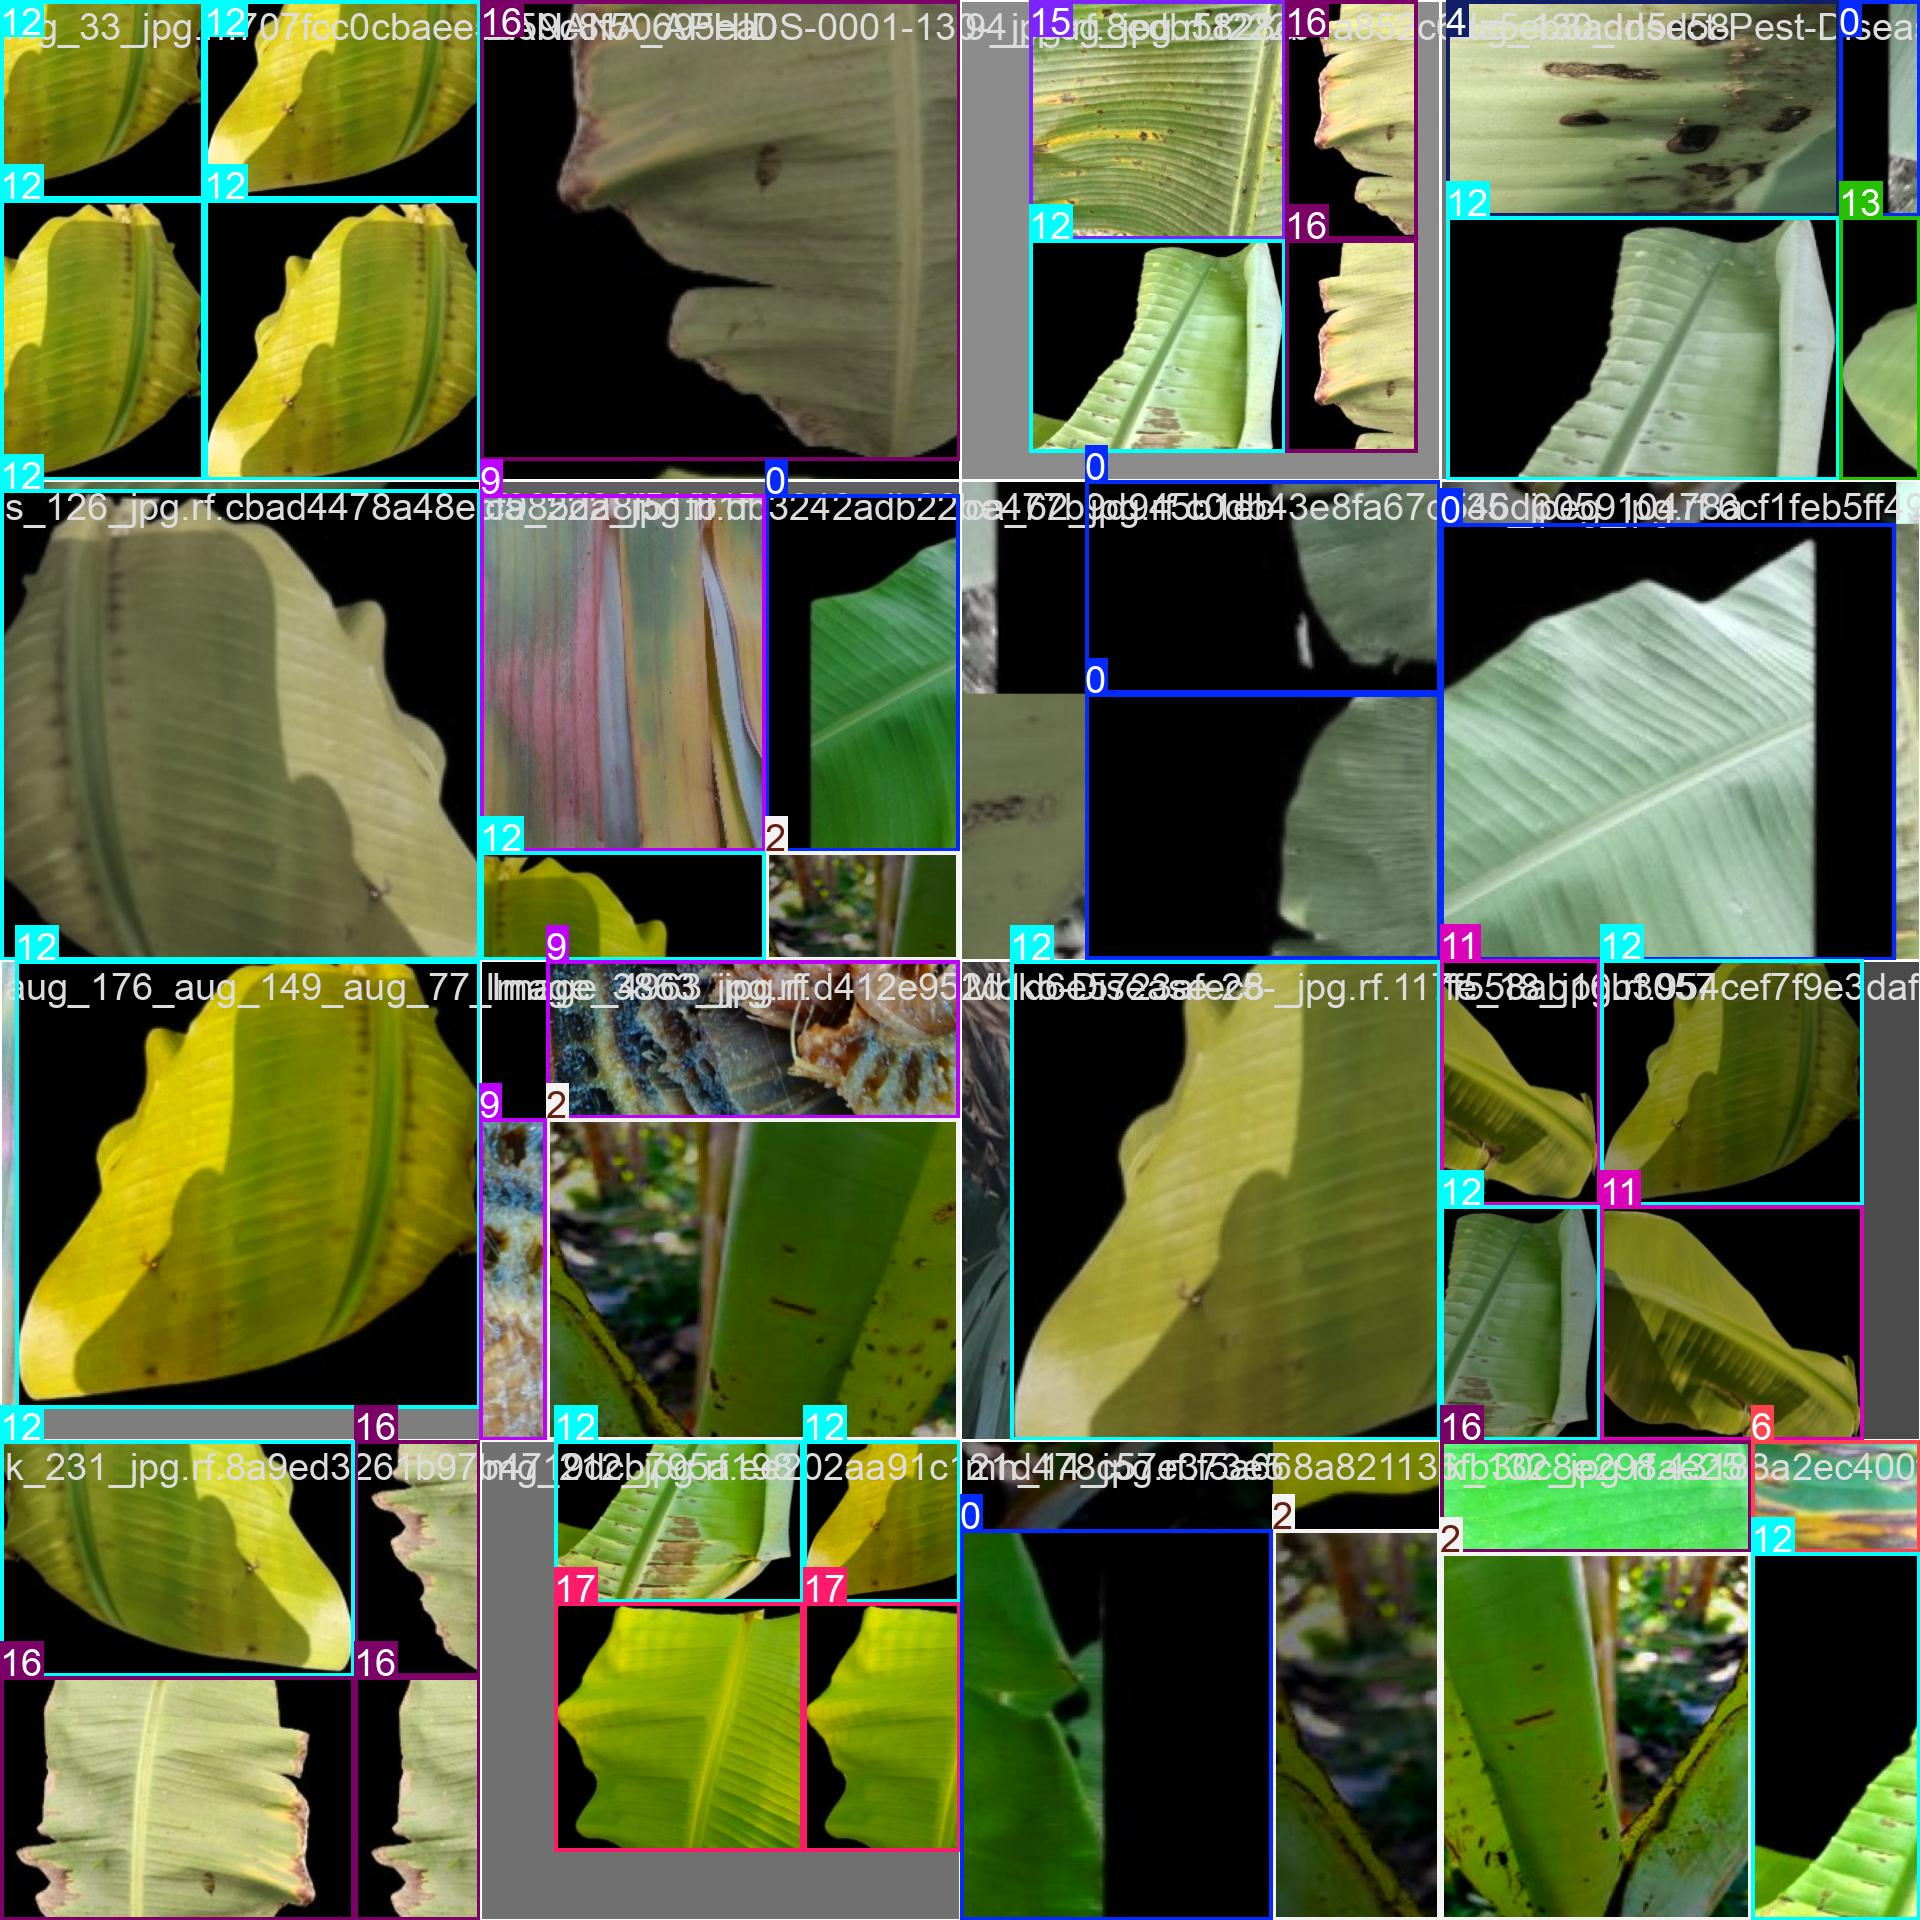

In [13]:
from IPython.display import Image

# Specify the file path of the image
image_path = '/content/drive/MyDrive/Final_Project/Banana/Banana_Results/runs/detect/train2/train_batch0.jpg'

# Display the image
Image(filename=image_path, width=600)

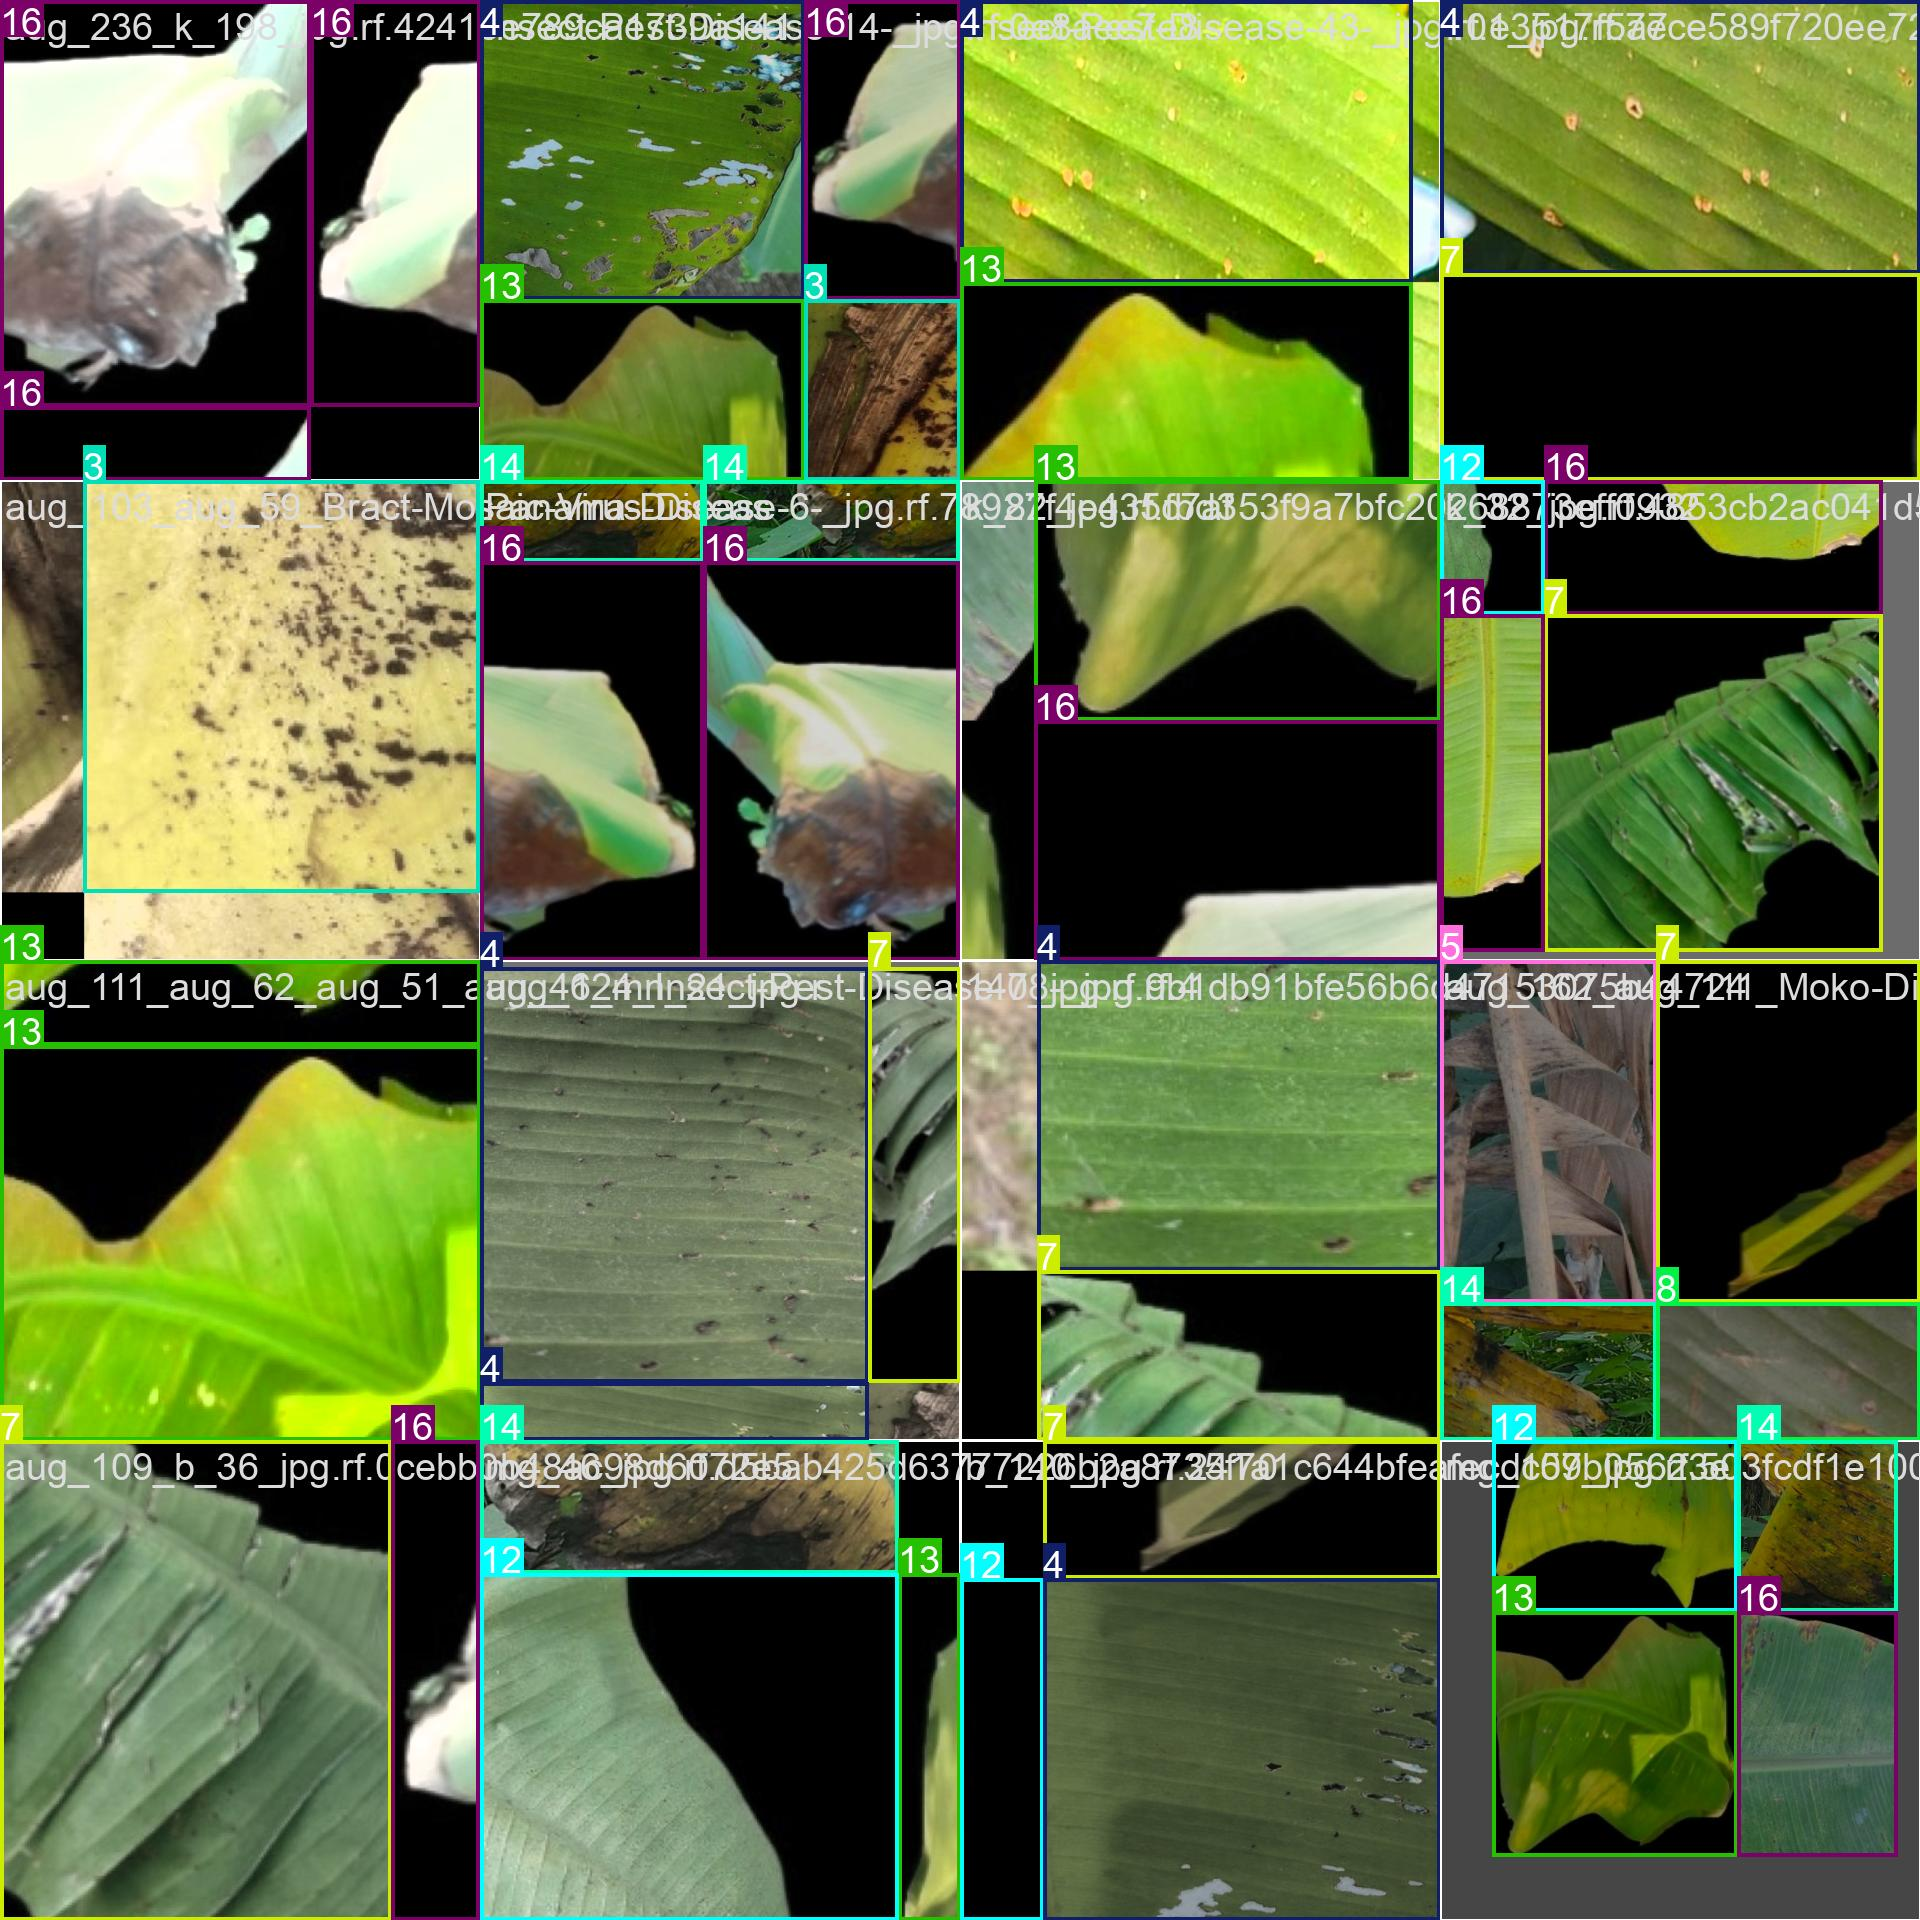

In [14]:
# Specify the file path of the image
image_path = '/content/drive/MyDrive/Final_Project/Banana/Banana_Results/runs/detect/train2/train_batch1.jpg'

# Display the image
Image(filename=image_path, width=600)

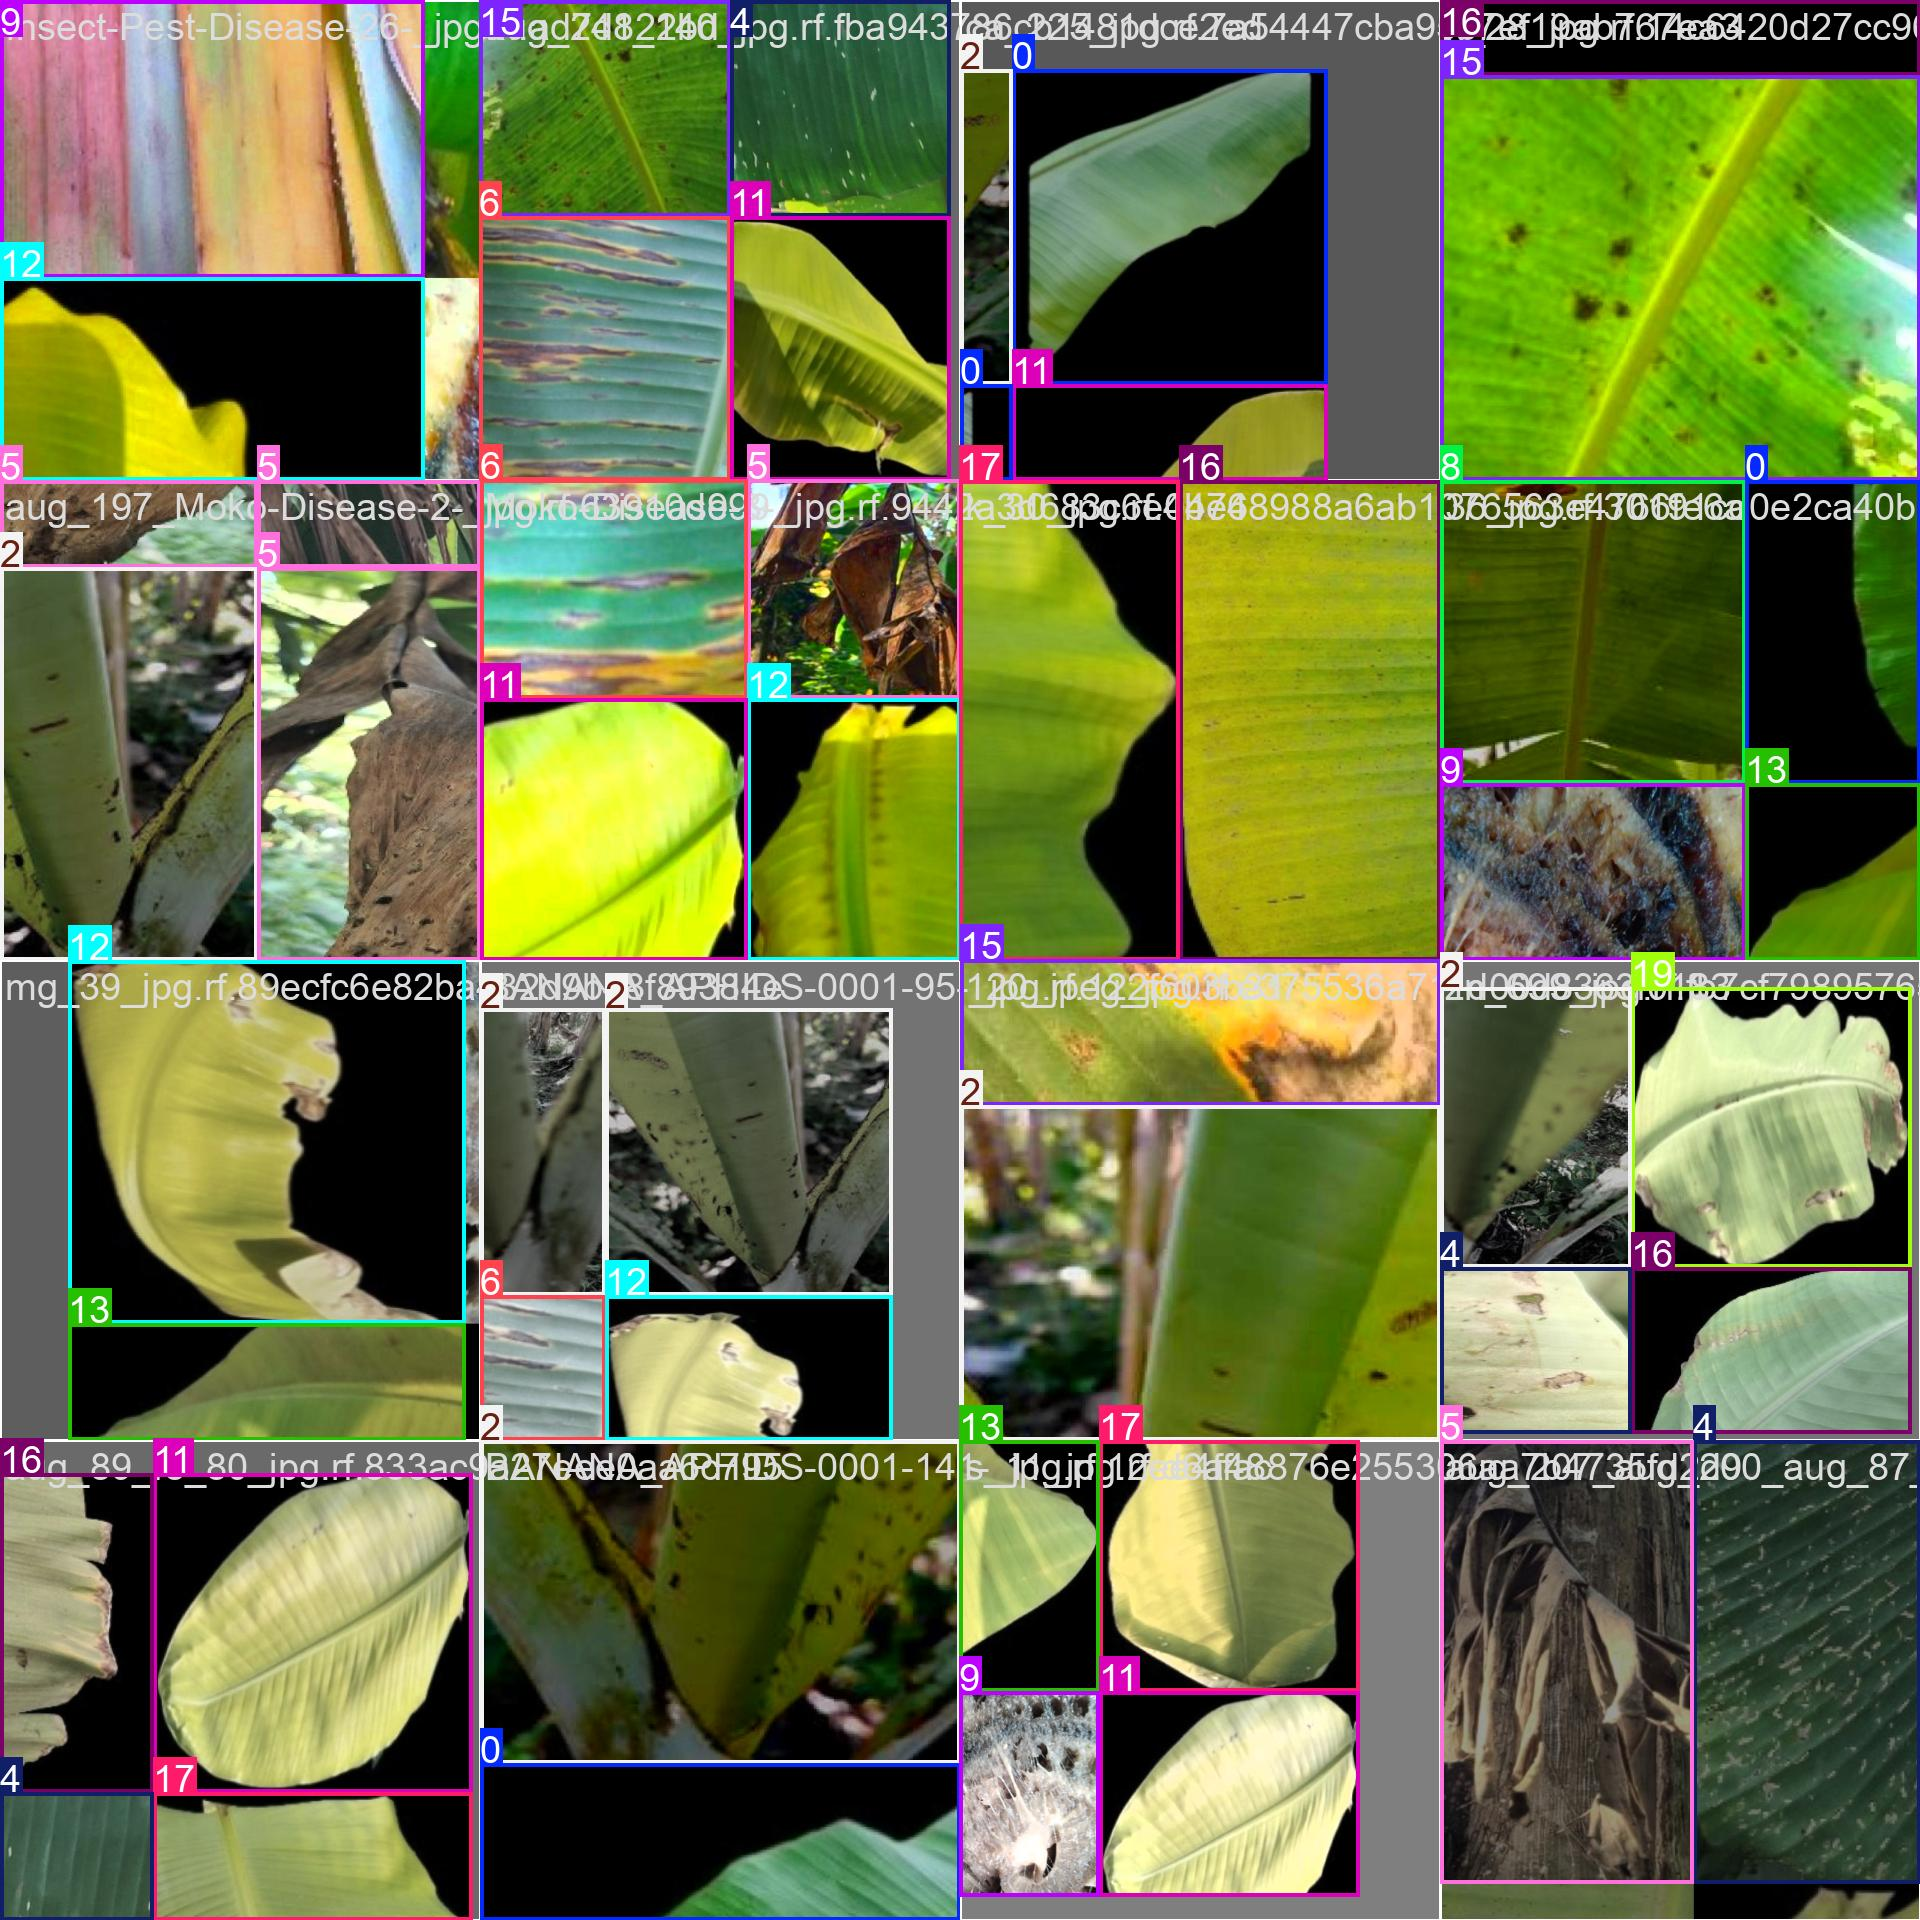

In [15]:
# Specify the file path of the image
image_path = '/content/drive/MyDrive/Final_Project/Banana/Banana_Results/runs/detect/train2/train_batch2.jpg'

# Display the image
Image(filename=image_path, width=600)

In [18]:
!ls /content/drive/MyDrive/Final_Project/Banana/Banana_Results/runs/detect/train2

args.yaml			 R_curve.png	      train_batch6082.jpg
confusion_matrix_normalized.png  results.csv	      val_batch0_labels.jpg
confusion_matrix.png		 results.png	      val_batch0_pred.jpg
F1_curve.png			 train_batch0.jpg     val_batch1_labels.jpg
labels_correlogram.jpg		 train_batch1.jpg     val_batch1_pred.jpg
labels.jpg			 train_batch2.jpg     val_batch2_labels.jpg
P_curve.png			 train_batch6080.jpg  val_batch2_pred.jpg
PR_curve.png			 train_batch6081.jpg  weights


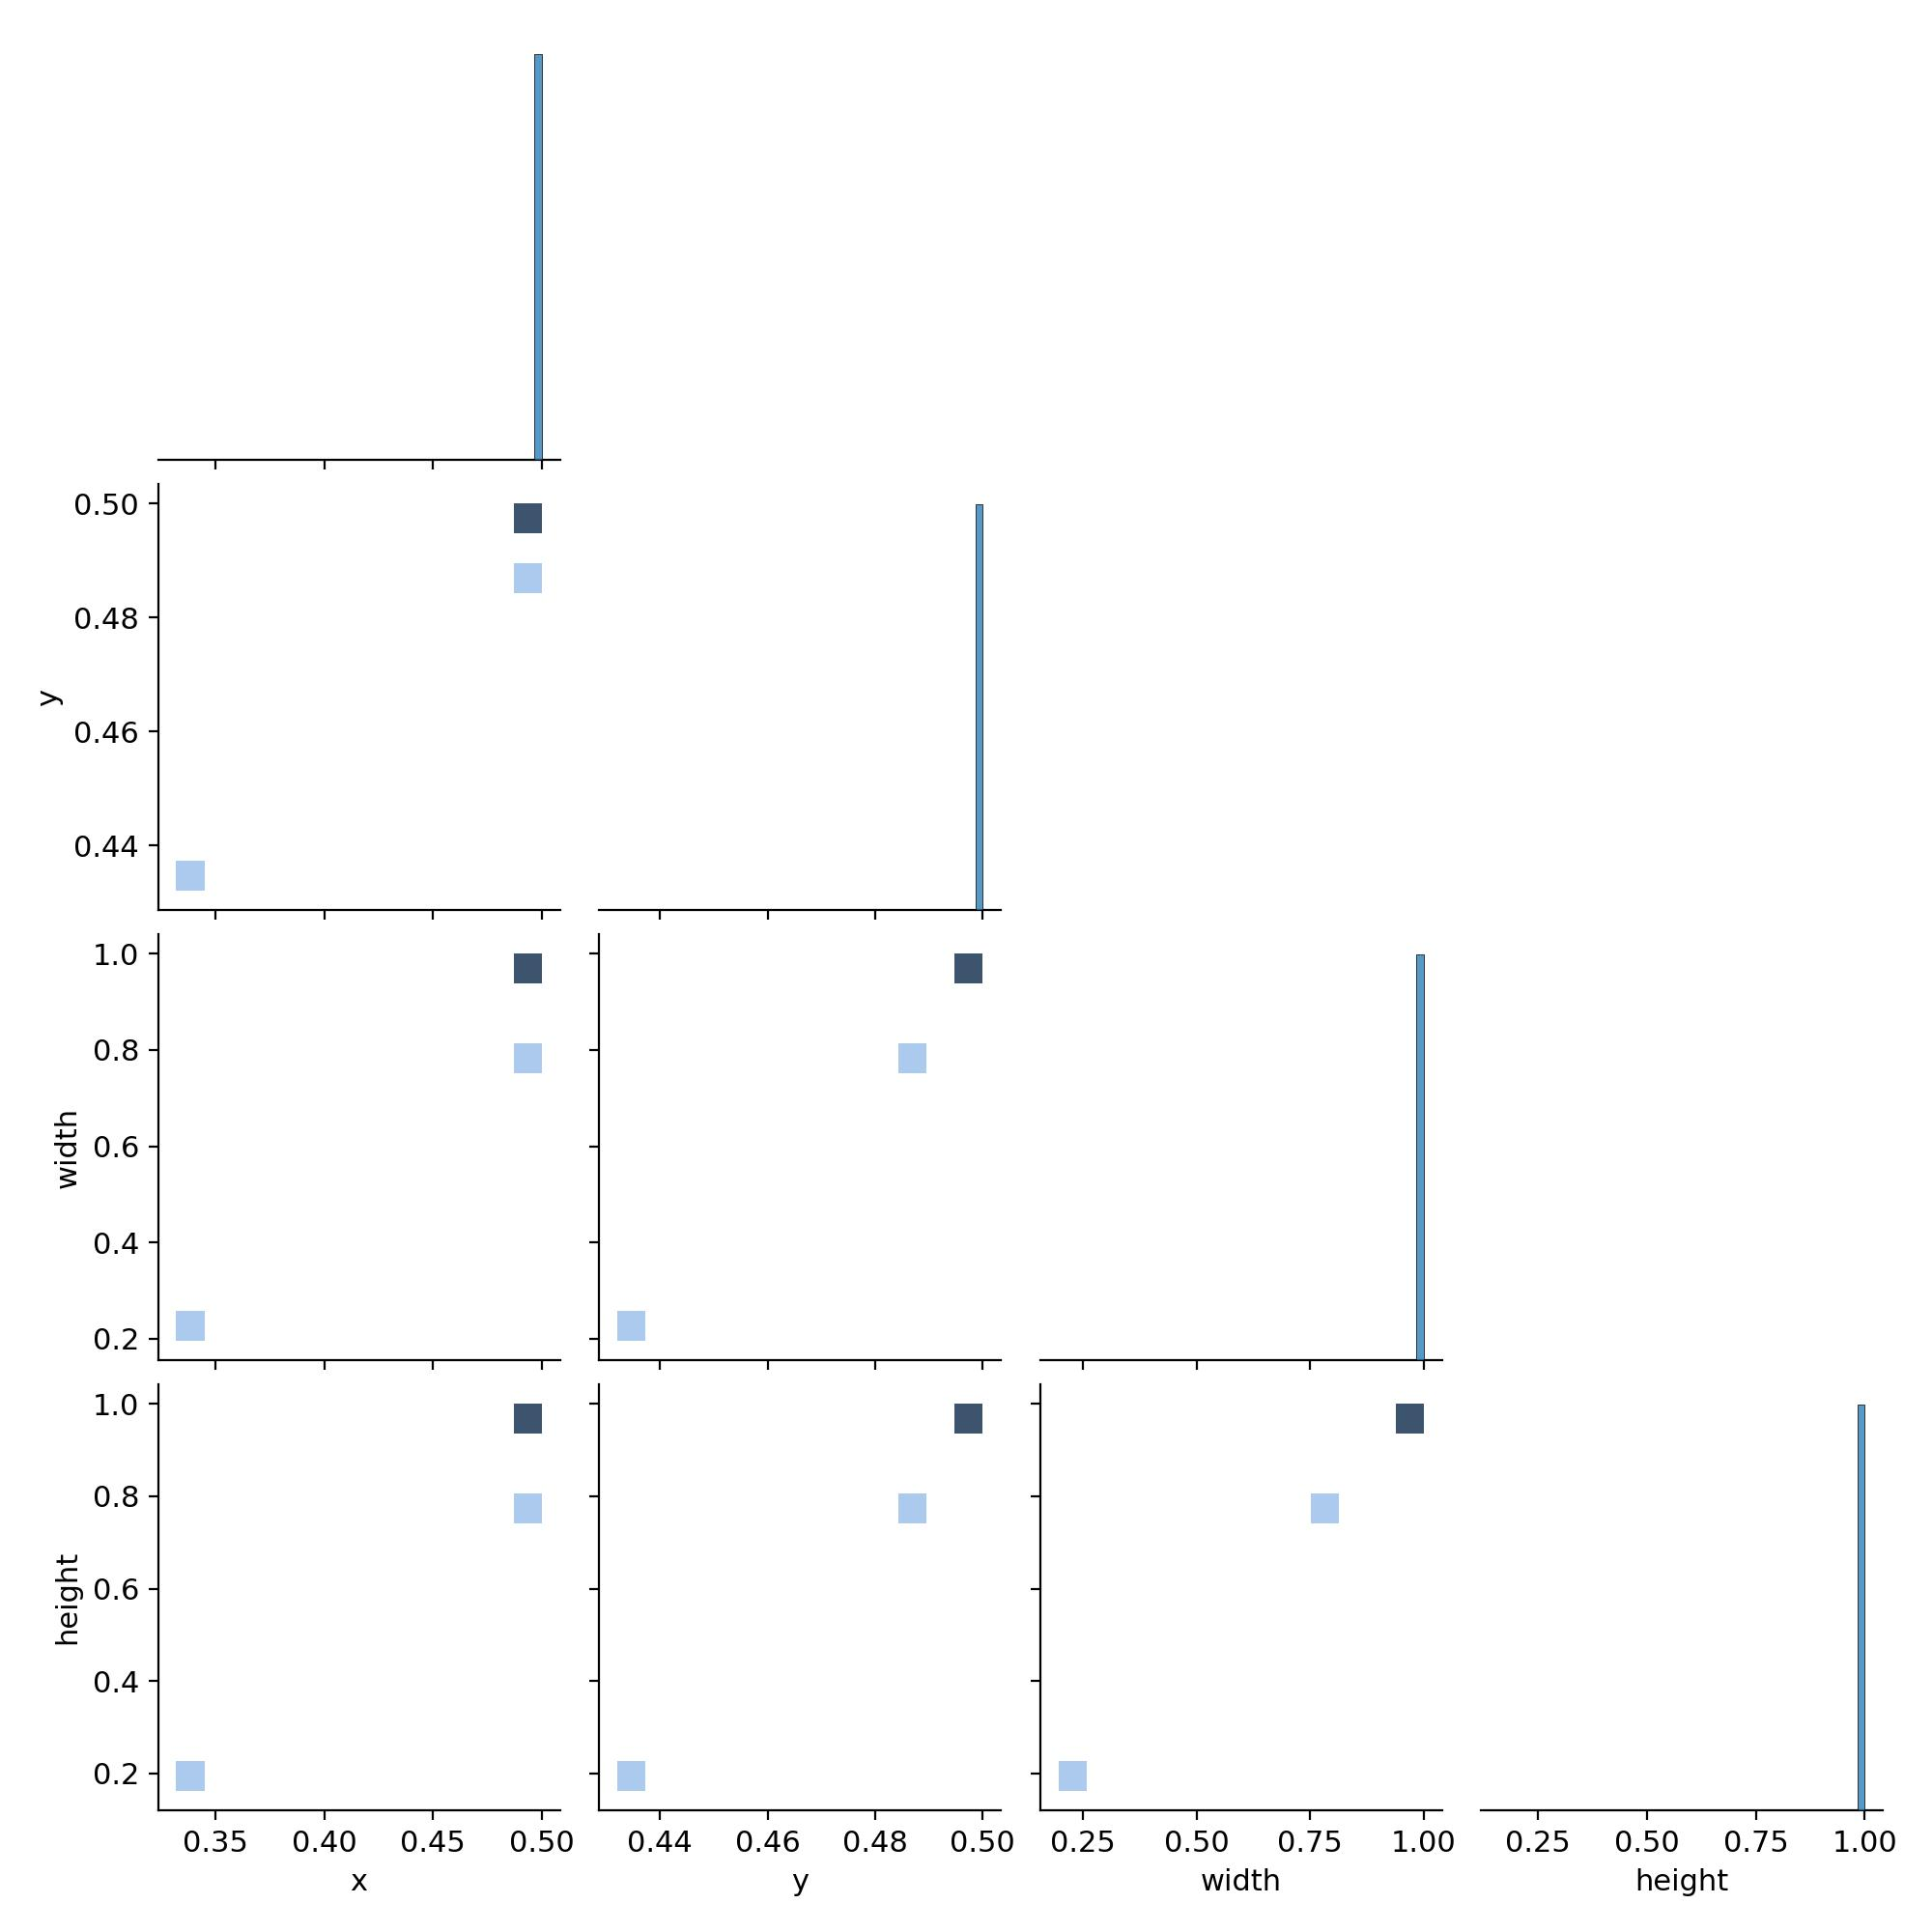

In [19]:
Image(filename=f'/content/drive/MyDrive/Final_Project/Banana/Banana_Results/runs/detect/train2/labels_correlogram.jpg', width=600)

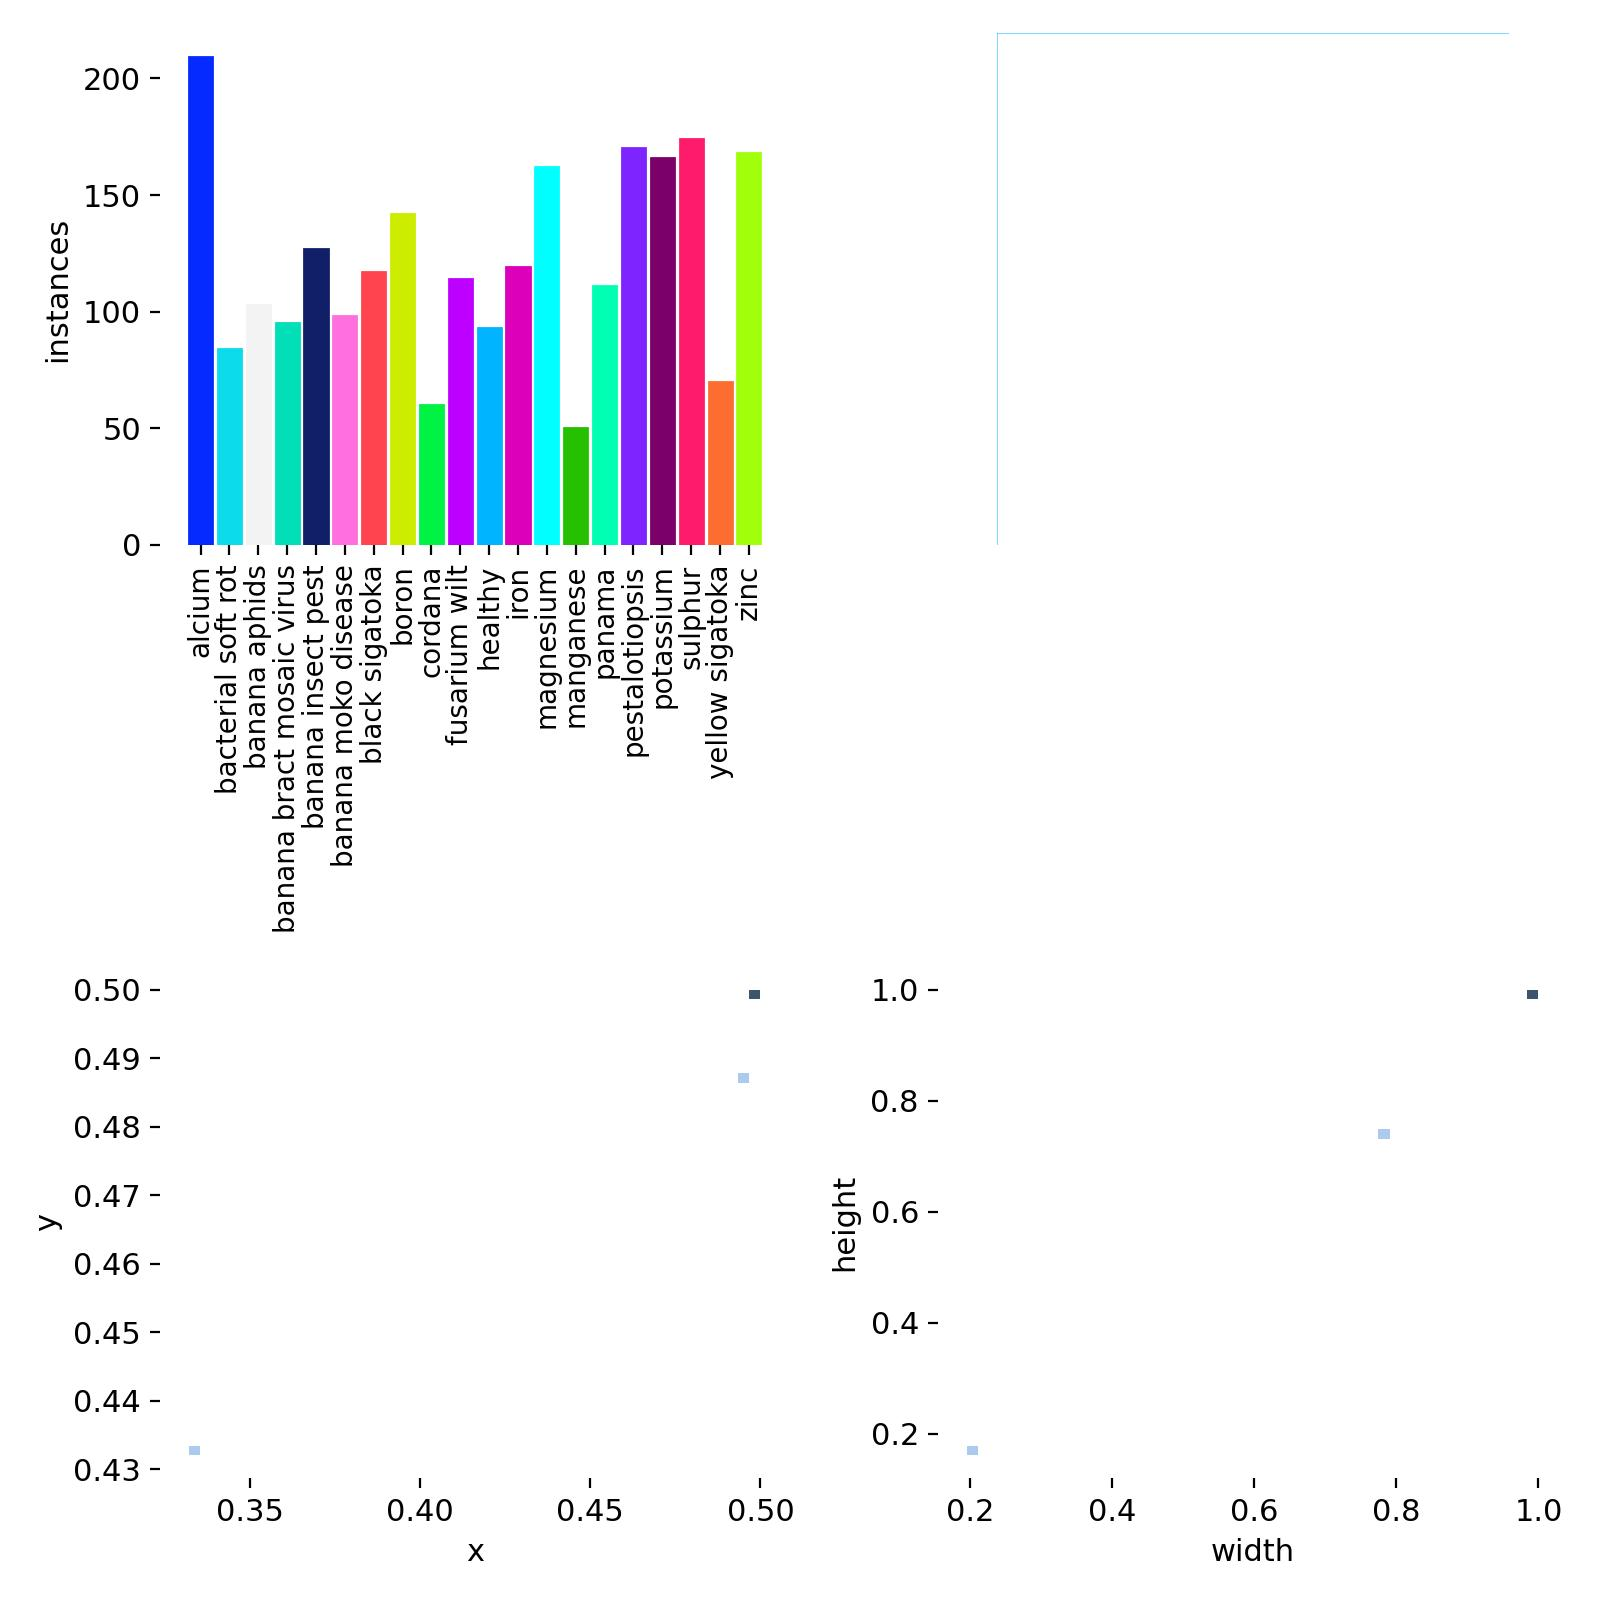

In [20]:
from IPython.display import Image

# Specify the file path of the image
image_path = '/content/drive/MyDrive/Final_Project/Banana/Banana_Results/runs/detect/train2/labels.jpg'

# Display the image
Image(filename=image_path, width=600)

In [21]:
import csv
from prettytable import PrettyTable

def print_yolov8_results(csv_file):
    try:
        with open(csv_file, newline='') as csvfile:
            reader = csv.reader(csvfile)
            # Initialize a PrettyTable object
            table = PrettyTable()
            # Read the header row
            headers = next(reader)
            # Set the column headers
            table.field_names = headers
            # Add rows to the table
            for row in reader:
                table.add_row(row)
            # Print the table
            print(table)
    except FileNotFoundError:
        print(f"The file {csv_file} does not exist.")

# Provide the path to your YOLOv8 results CSV file
csv_file_path = "/content/drive/MyDrive/Final_Project/Banana/Banana_Results/runs/detect/train2/results.csv"

# Call the function to print YOLOv8 results in table form
print_yolov8_results(csv_file_path)

+-------+---------+----------------+----------------+----------------+----------------------+-------------------+------------------+---------------------+--------------+--------------+--------------+-------------+-------------+-------------+
| epoch |   time  | train/box_loss | train/cls_loss | train/dfl_loss | metrics/precision(B) | metrics/recall(B) | metrics/mAP50(B) | metrics/mAP50-95(B) | val/box_loss | val/cls_loss | val/dfl_loss |    lr/pg0   |    lr/pg1   |    lr/pg2   |
+-------+---------+----------------+----------------+----------------+----------------------+-------------------+------------------+---------------------+--------------+--------------+--------------+-------------+-------------+-------------+
|   1   | 101.673 |    0.61775     |     3.7197     |    1.40084     |       0.36518        |      0.46005      |     0.27199      |       0.19871       |    0.8233    |   2.73841    |   1.37954    | 0.000138086 | 0.000138086 | 0.000138086 |
|   2   | 199.945 |    0.26701  

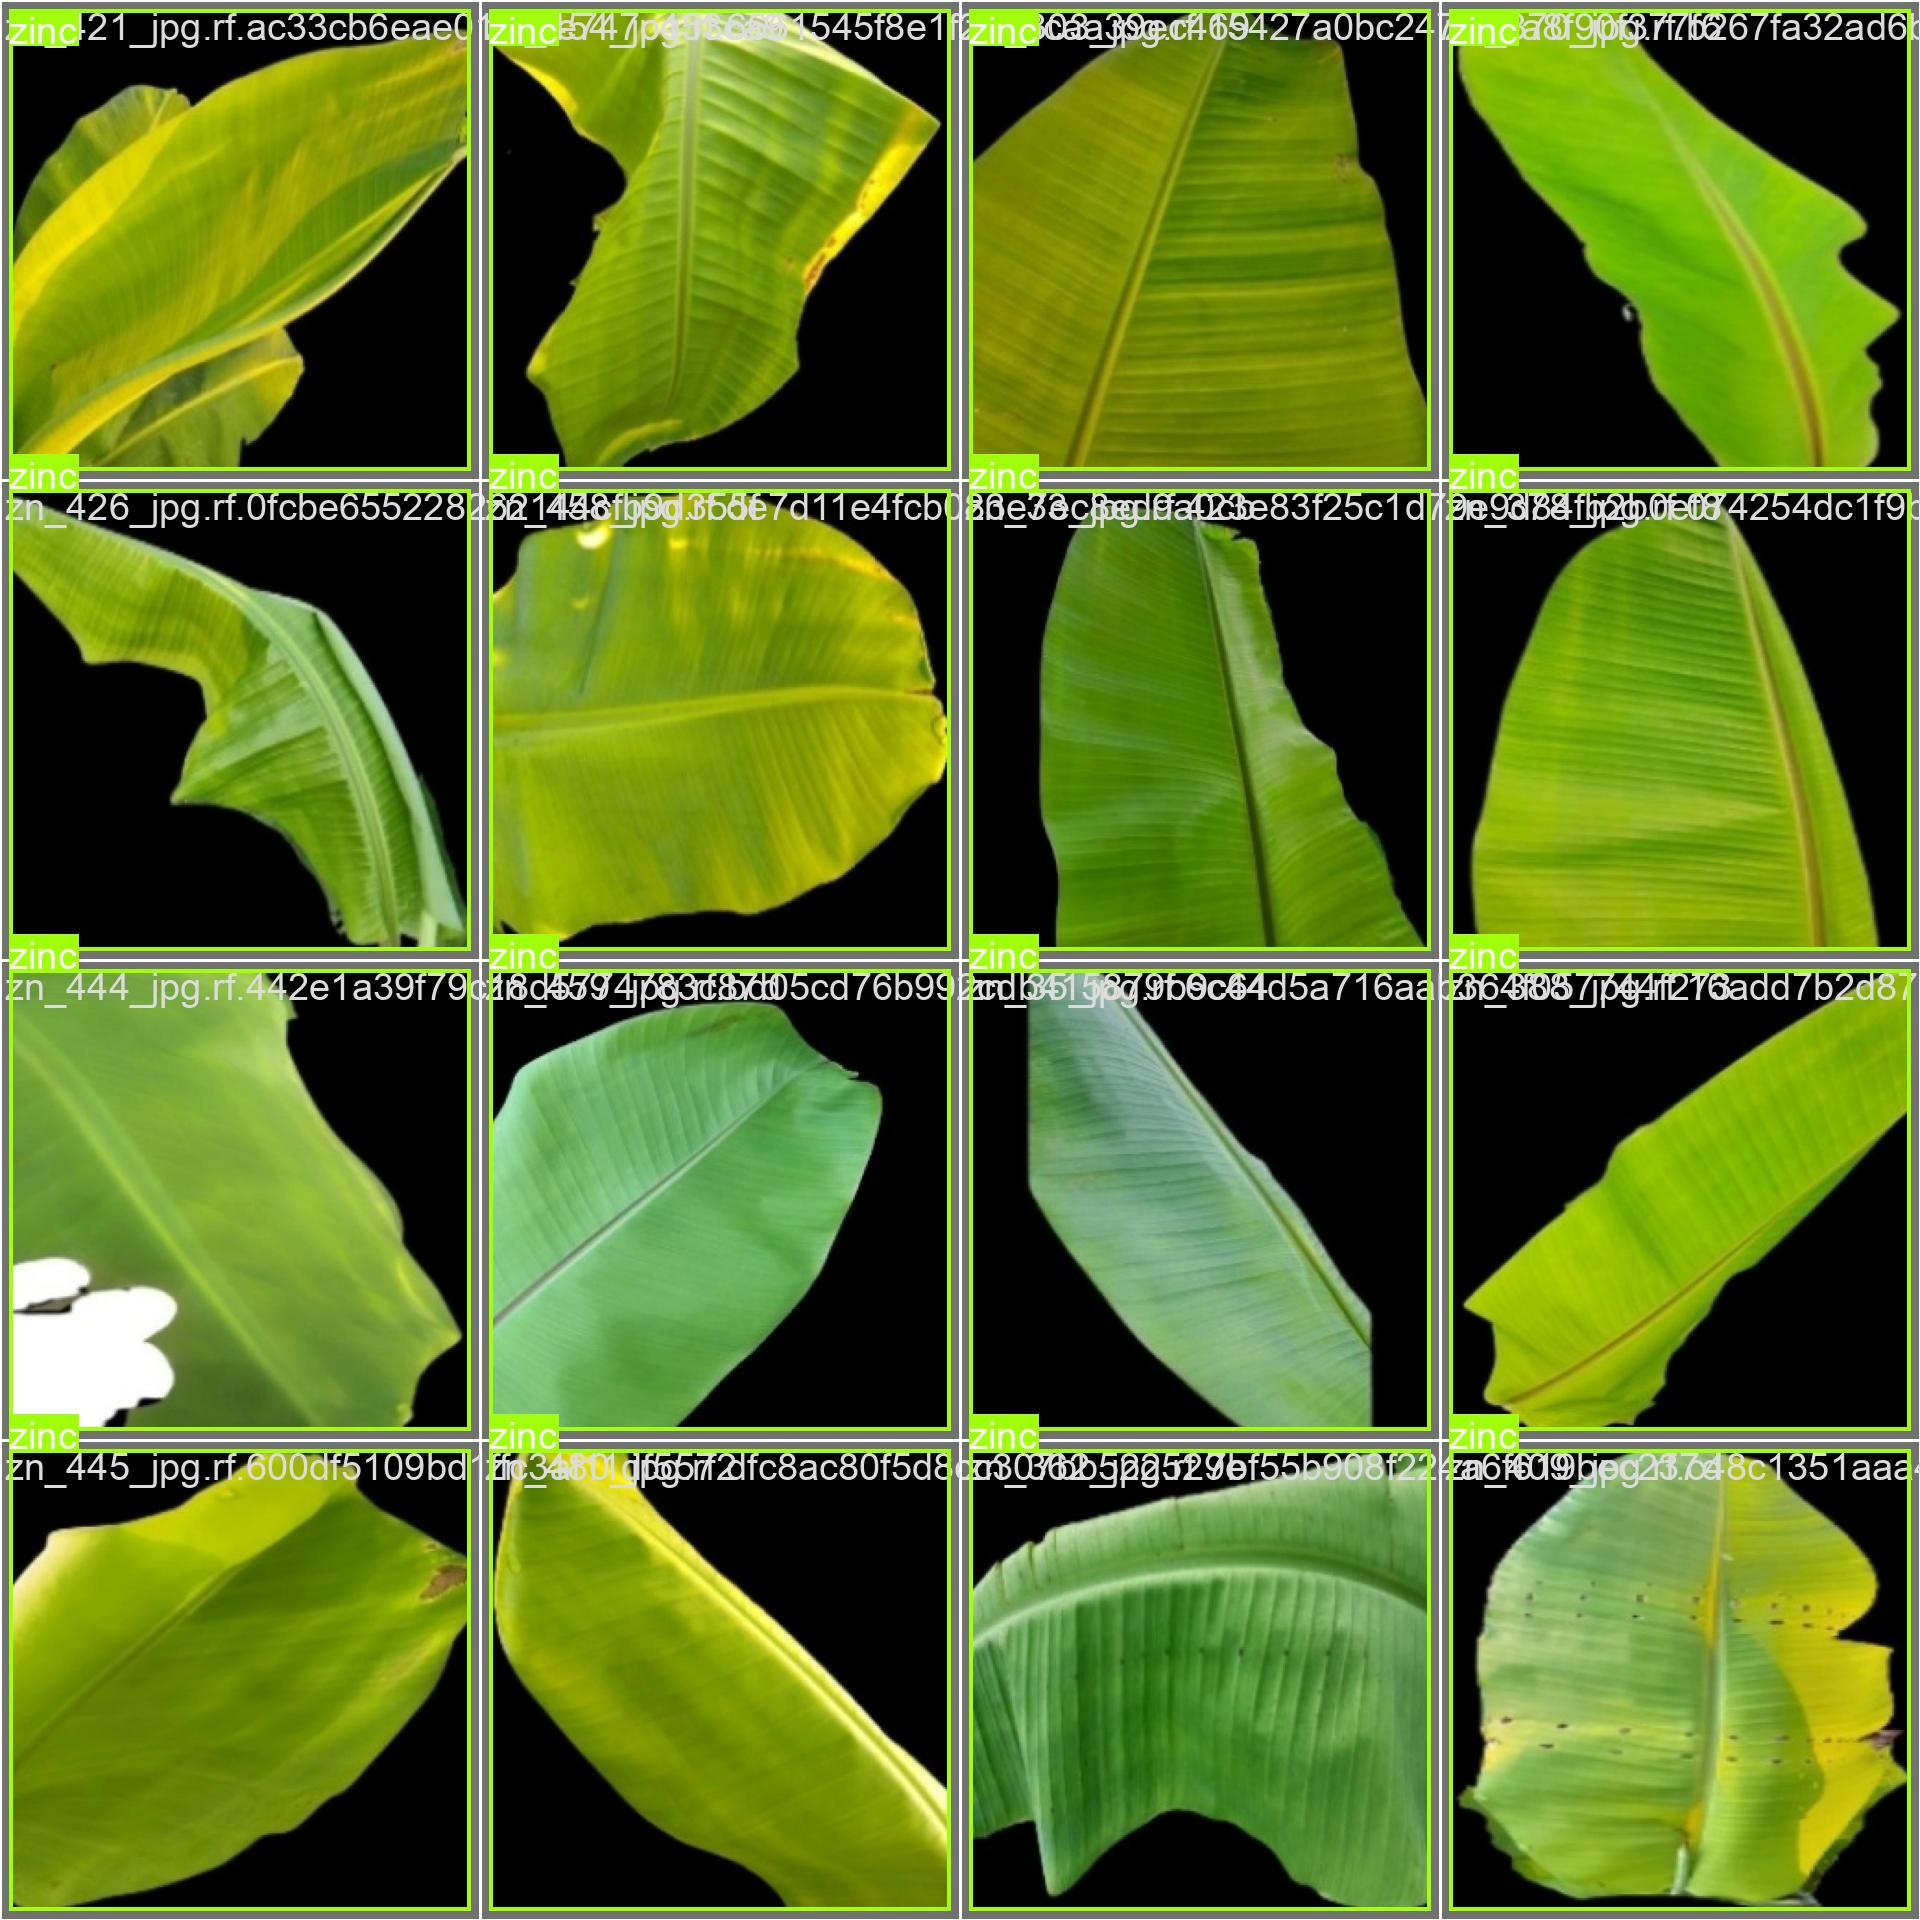

In [22]:
# Specify the file path of the image
image_path = '/content/drive/MyDrive/Final_Project/Banana/Banana_Results/runs/detect/train2/val_batch0_labels.jpg'

# Display the image
Image(filename=image_path, width=600)

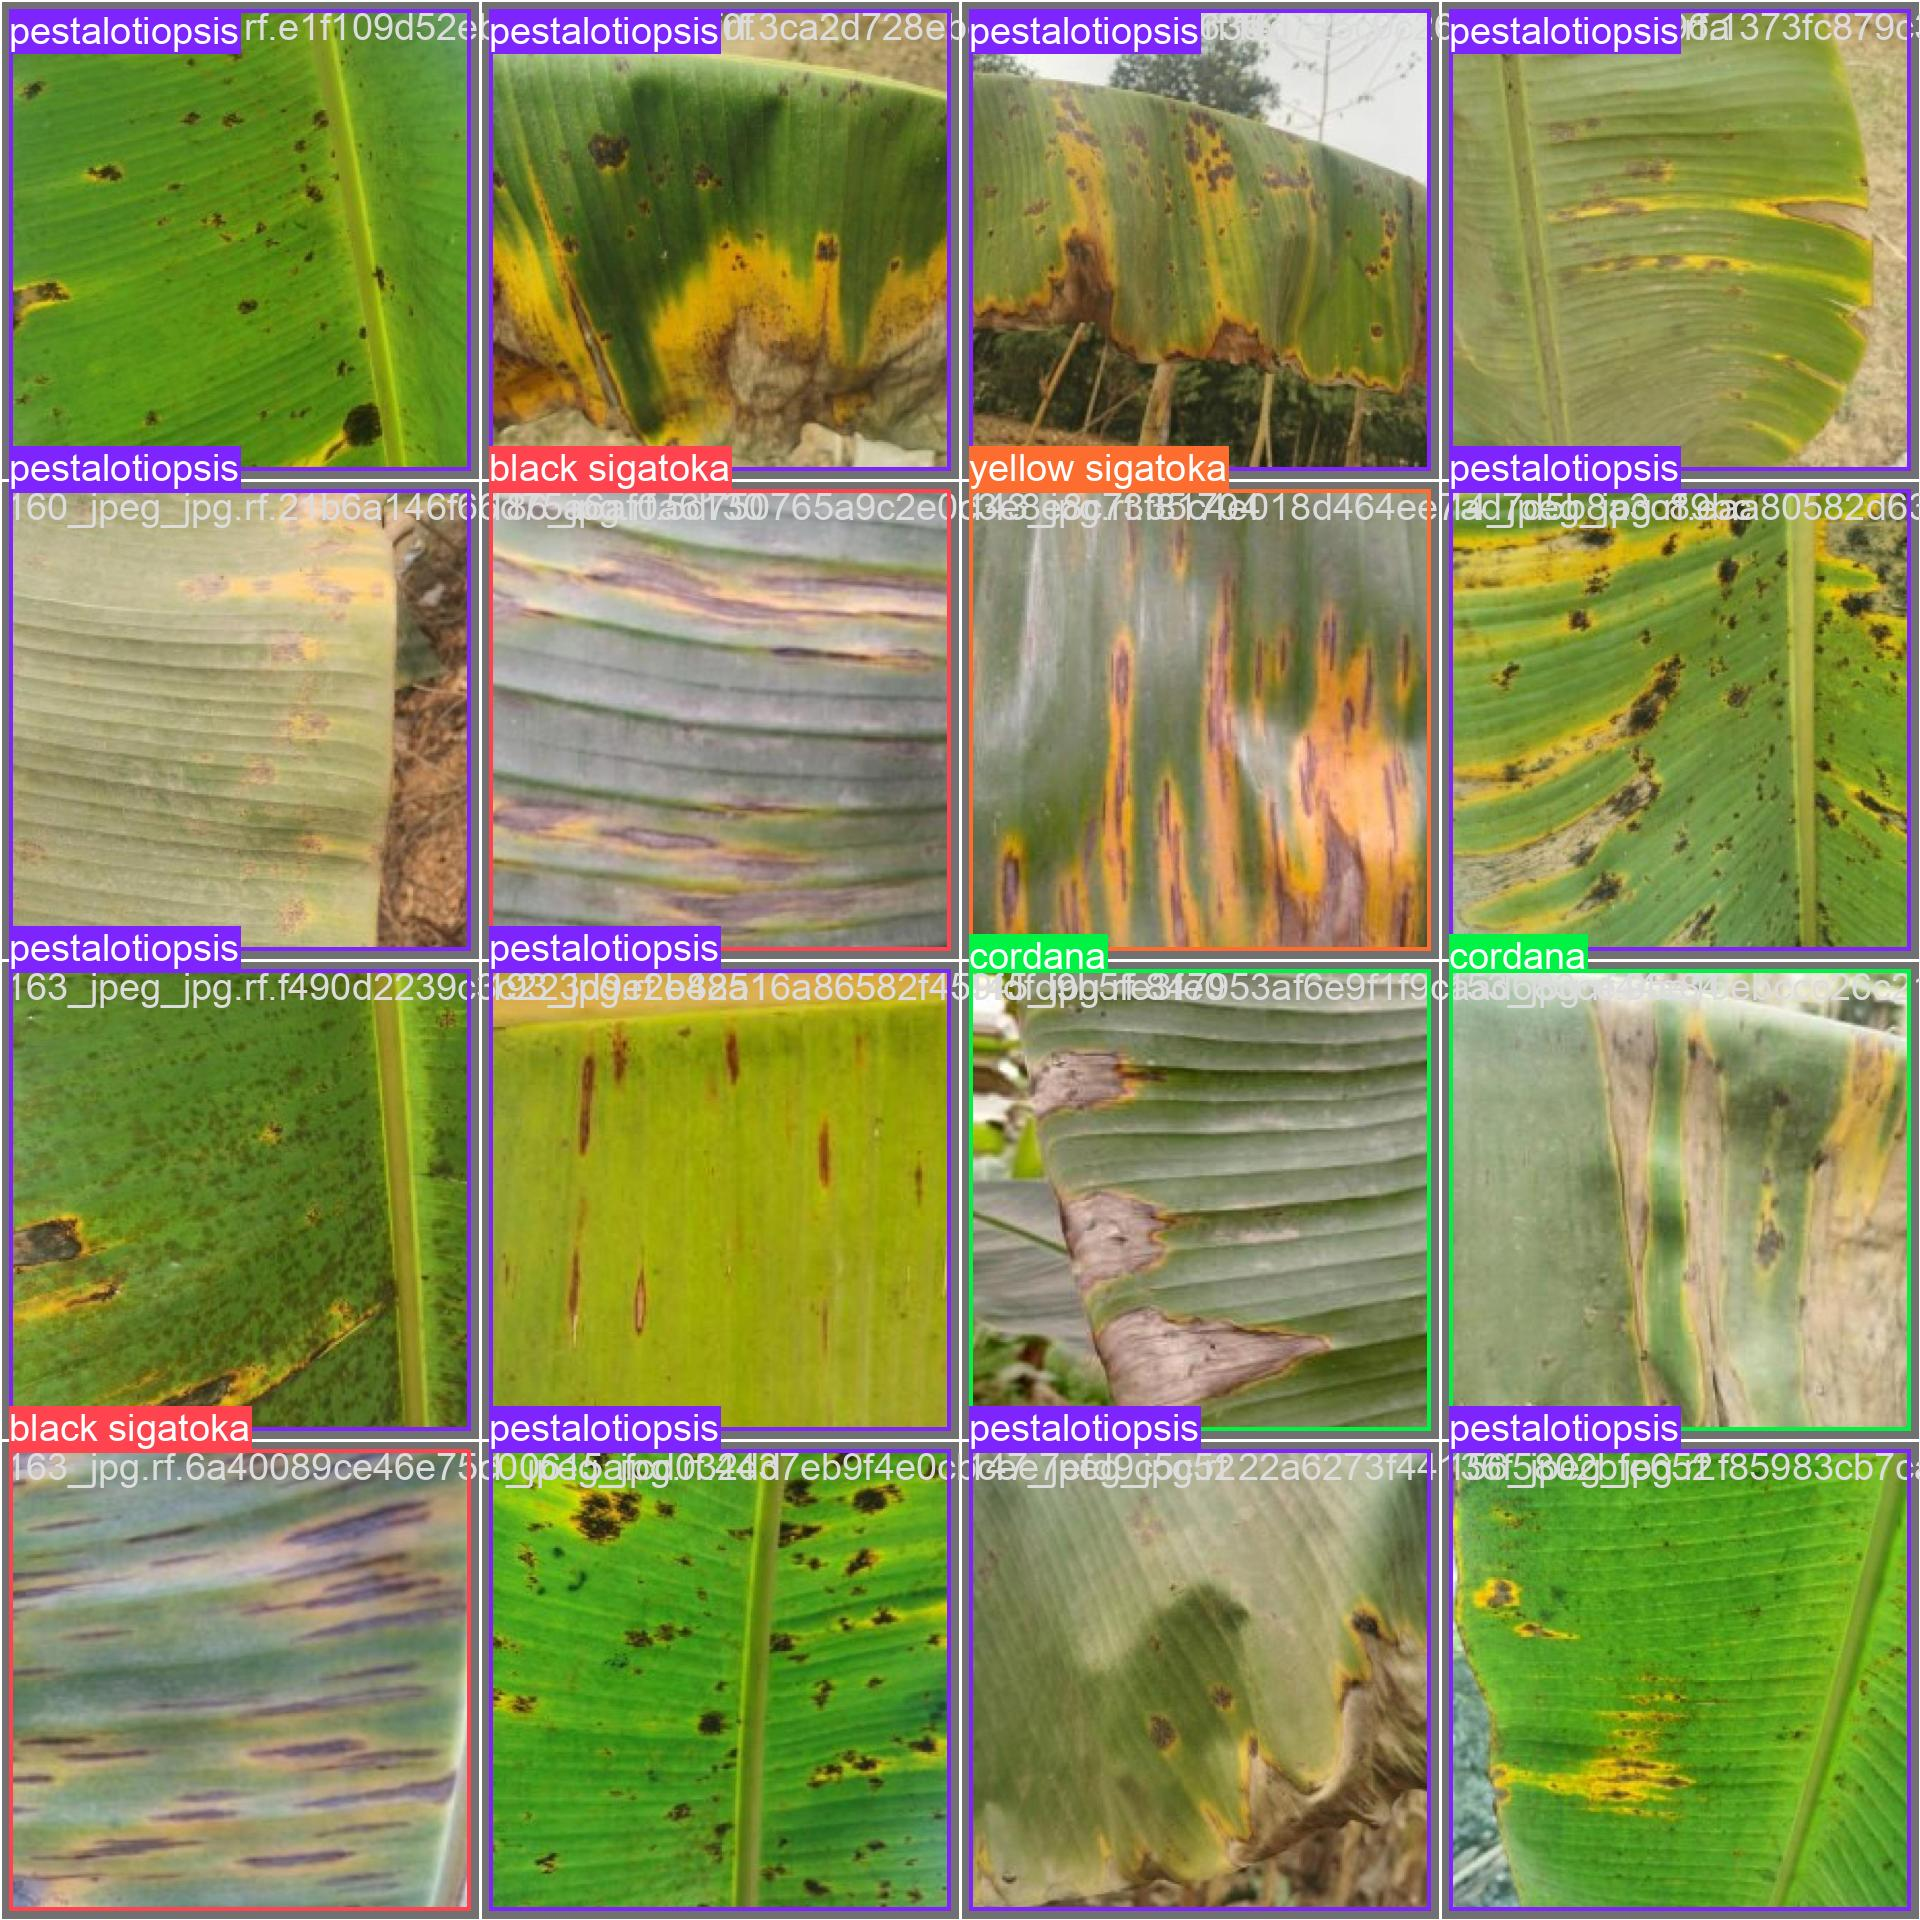

In [23]:
# Specify the file path of the image
image_path = '/content/drive/MyDrive/Final_Project/Banana/Banana_Results/runs/detect/train2/val_batch1_labels.jpg'

# Display the image
Image(filename=image_path, width=600)

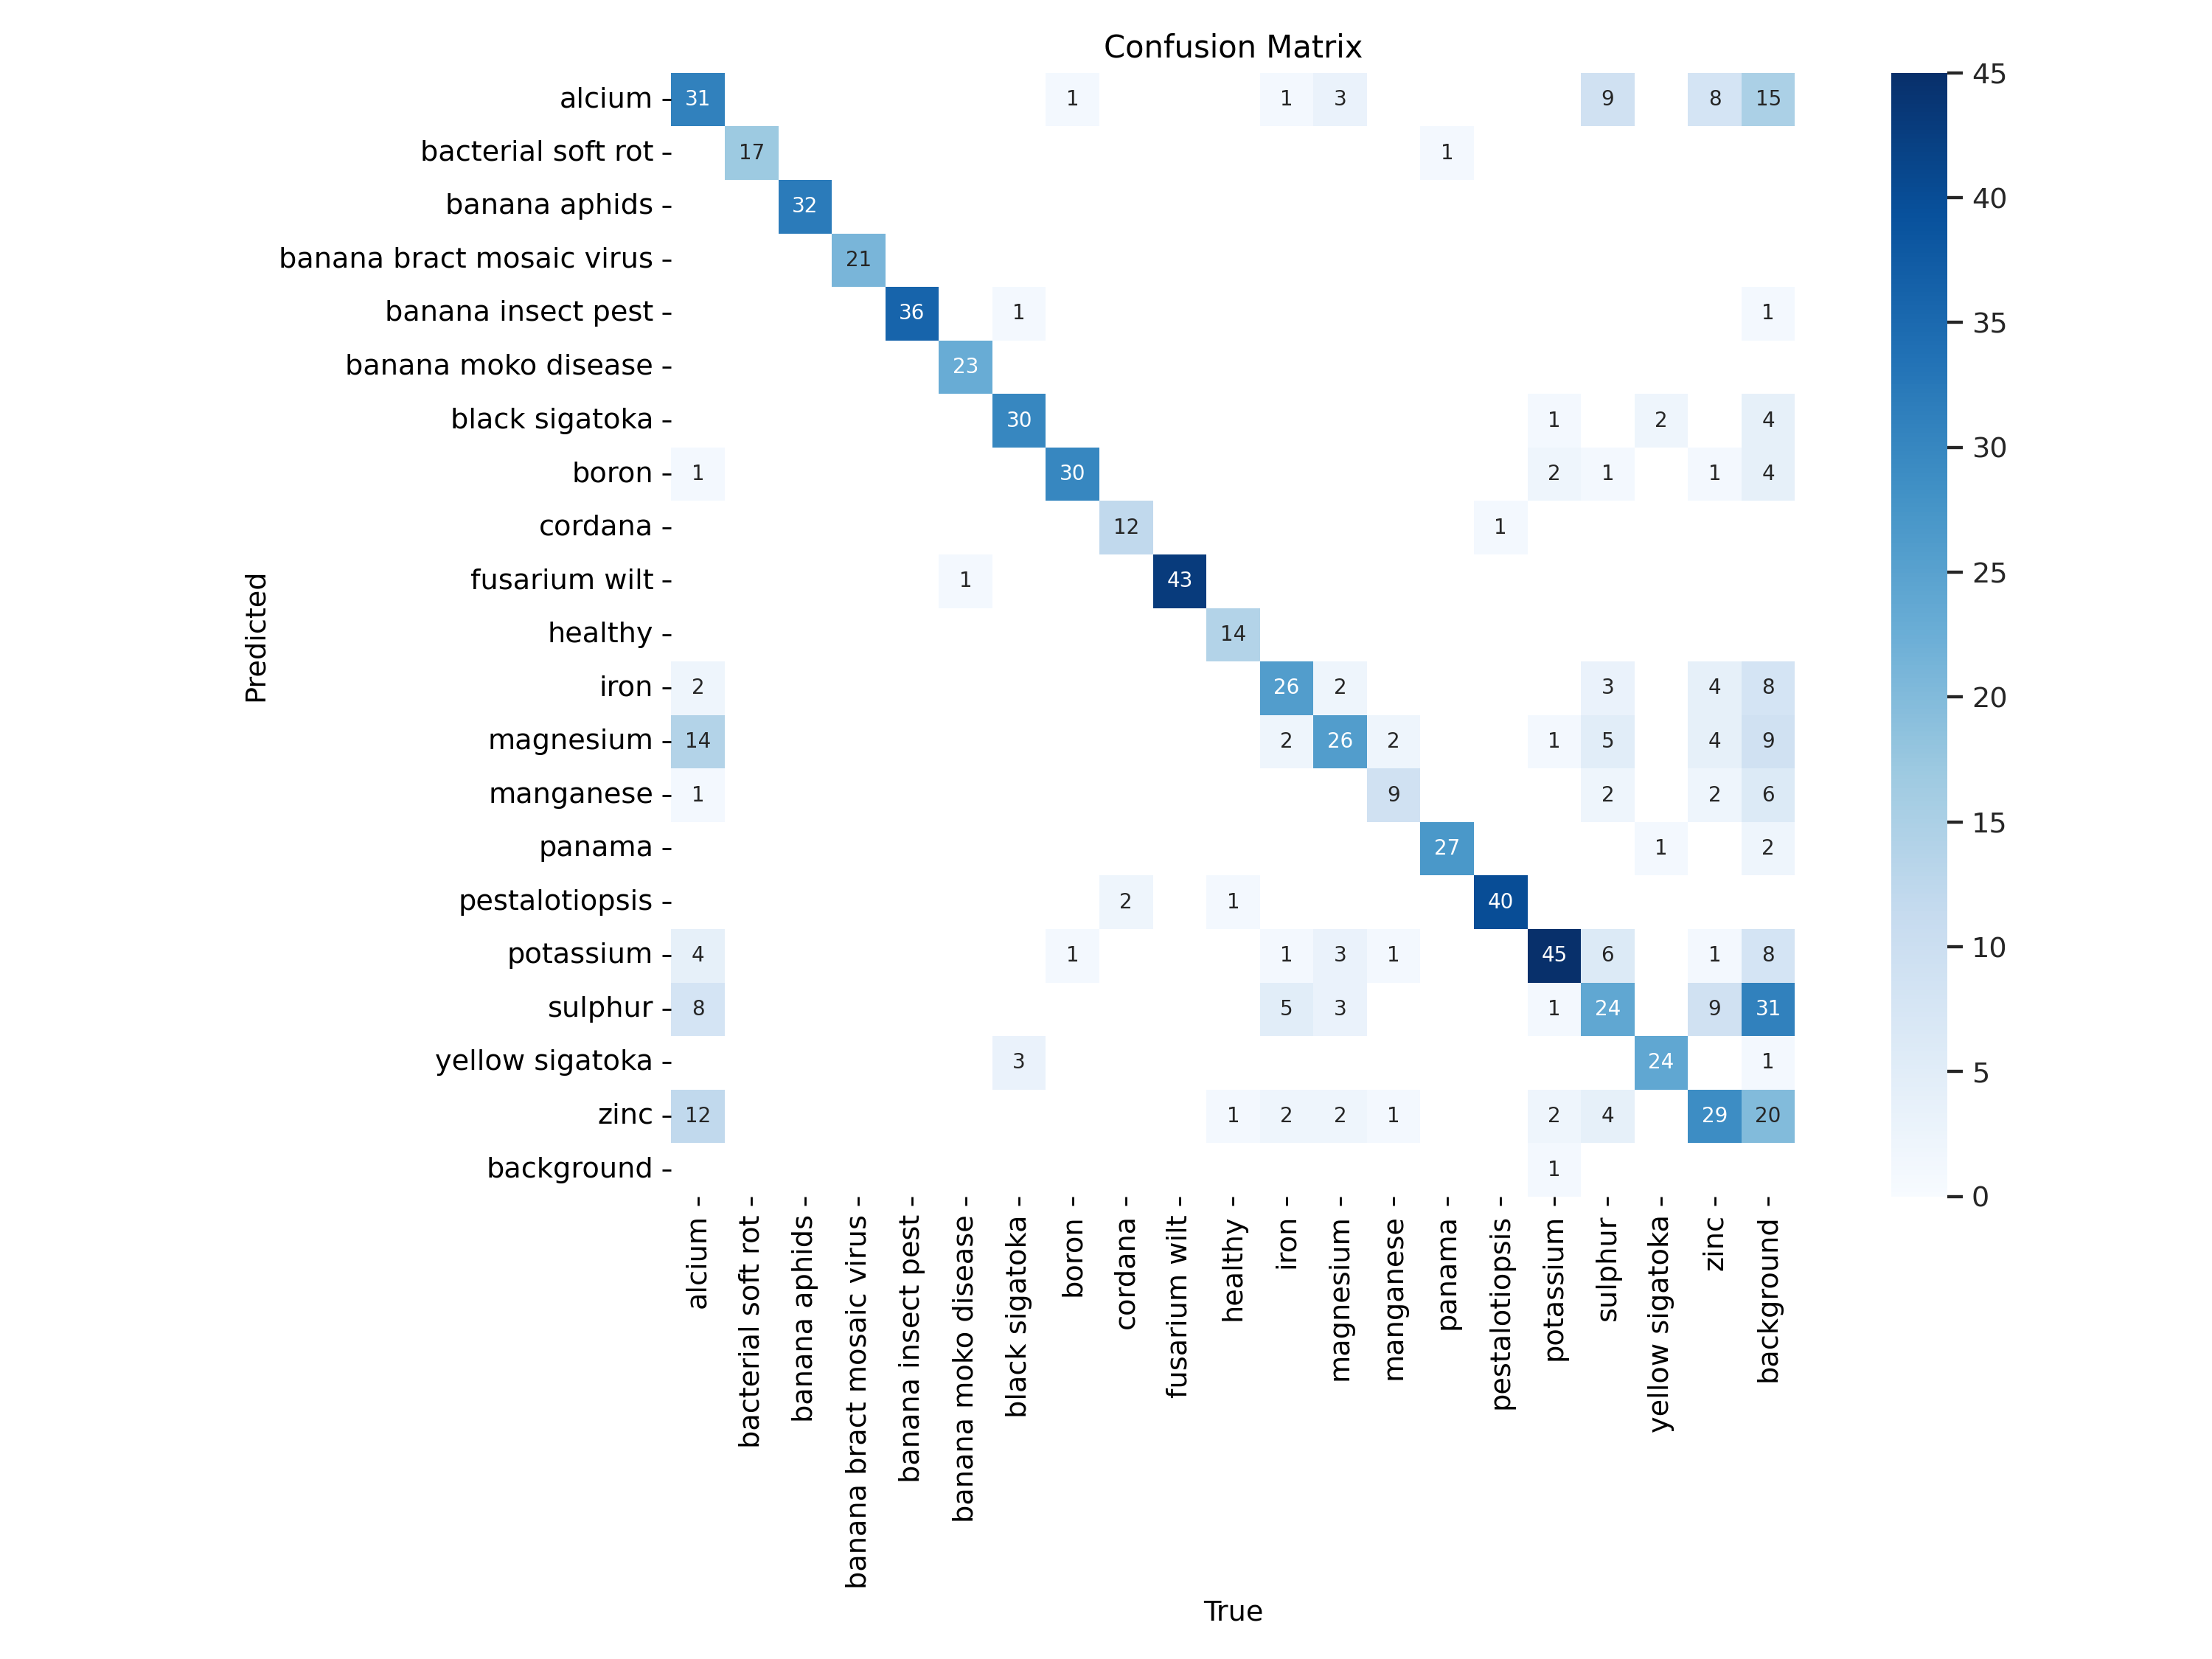

In [24]:
Image(filename=f'/content/drive/MyDrive/Final_Project/Banana/Banana_Results/runs/detect/train2/confusion_matrix.png', width=600)

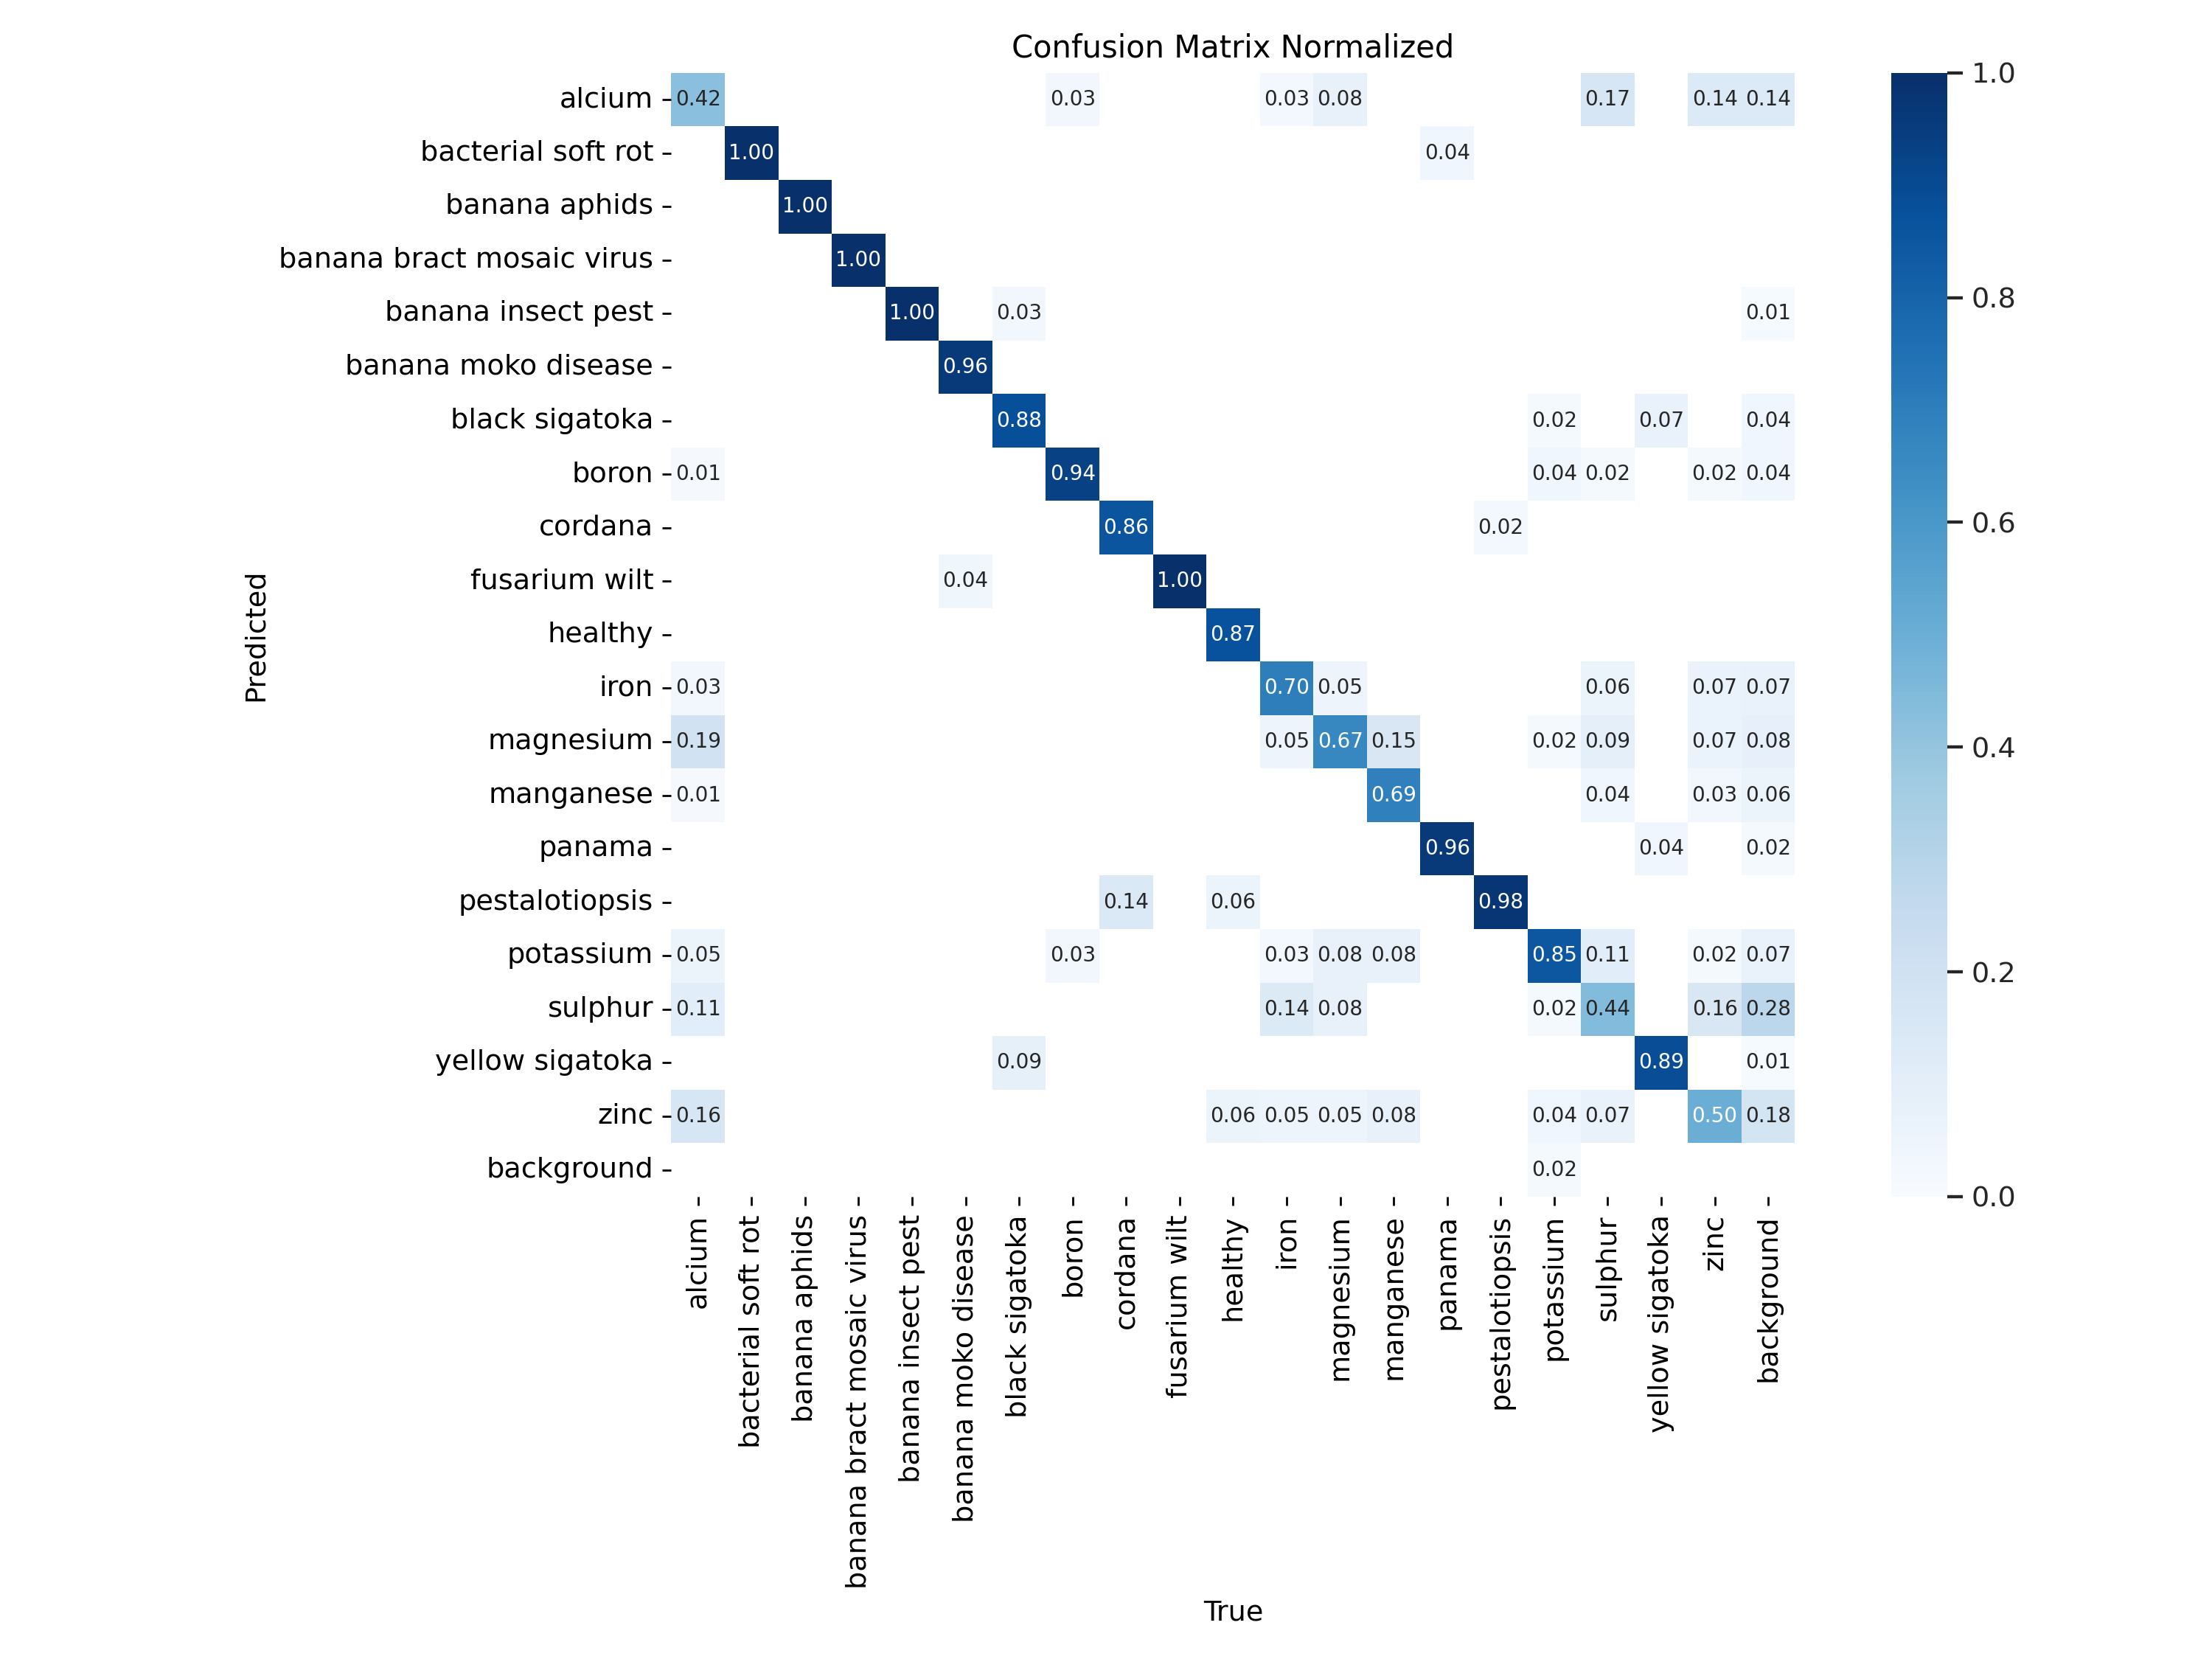

In [25]:
Image(filename=f'/content/drive/MyDrive/Final_Project/Banana/Banana_Results/runs/detect/train2/confusion_matrix_normalized.png', width=600)

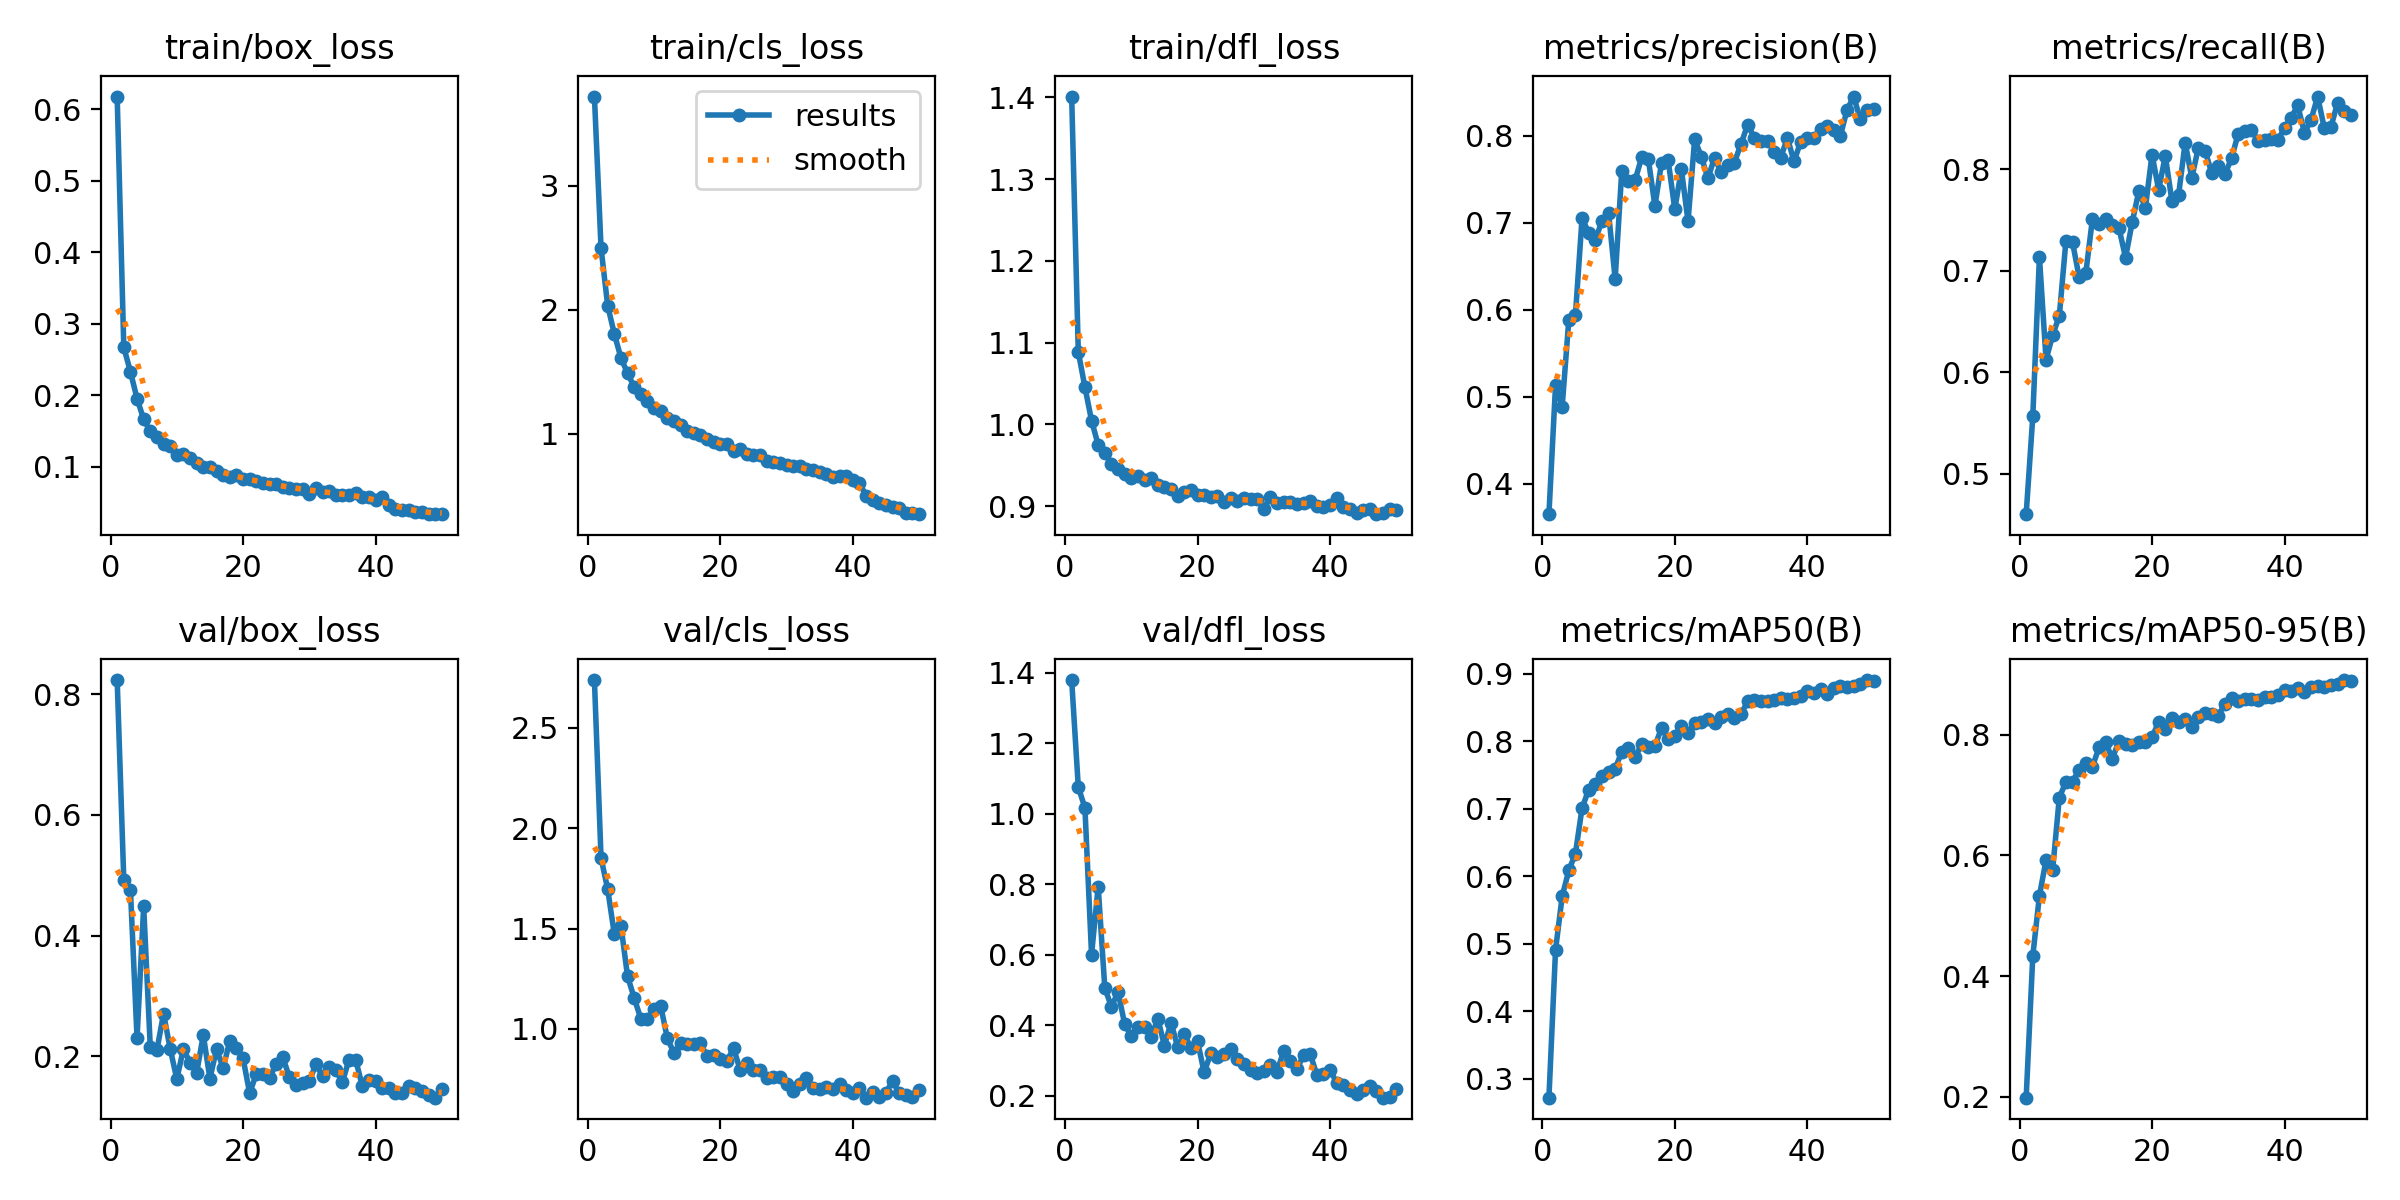

In [28]:
from IPython.display import Image

# Now you can use it to display the image
Image(filename='/content/drive/MyDrive/Final_Project/Banana/Banana_Results/runs/detect/train2/results.png', width=600)


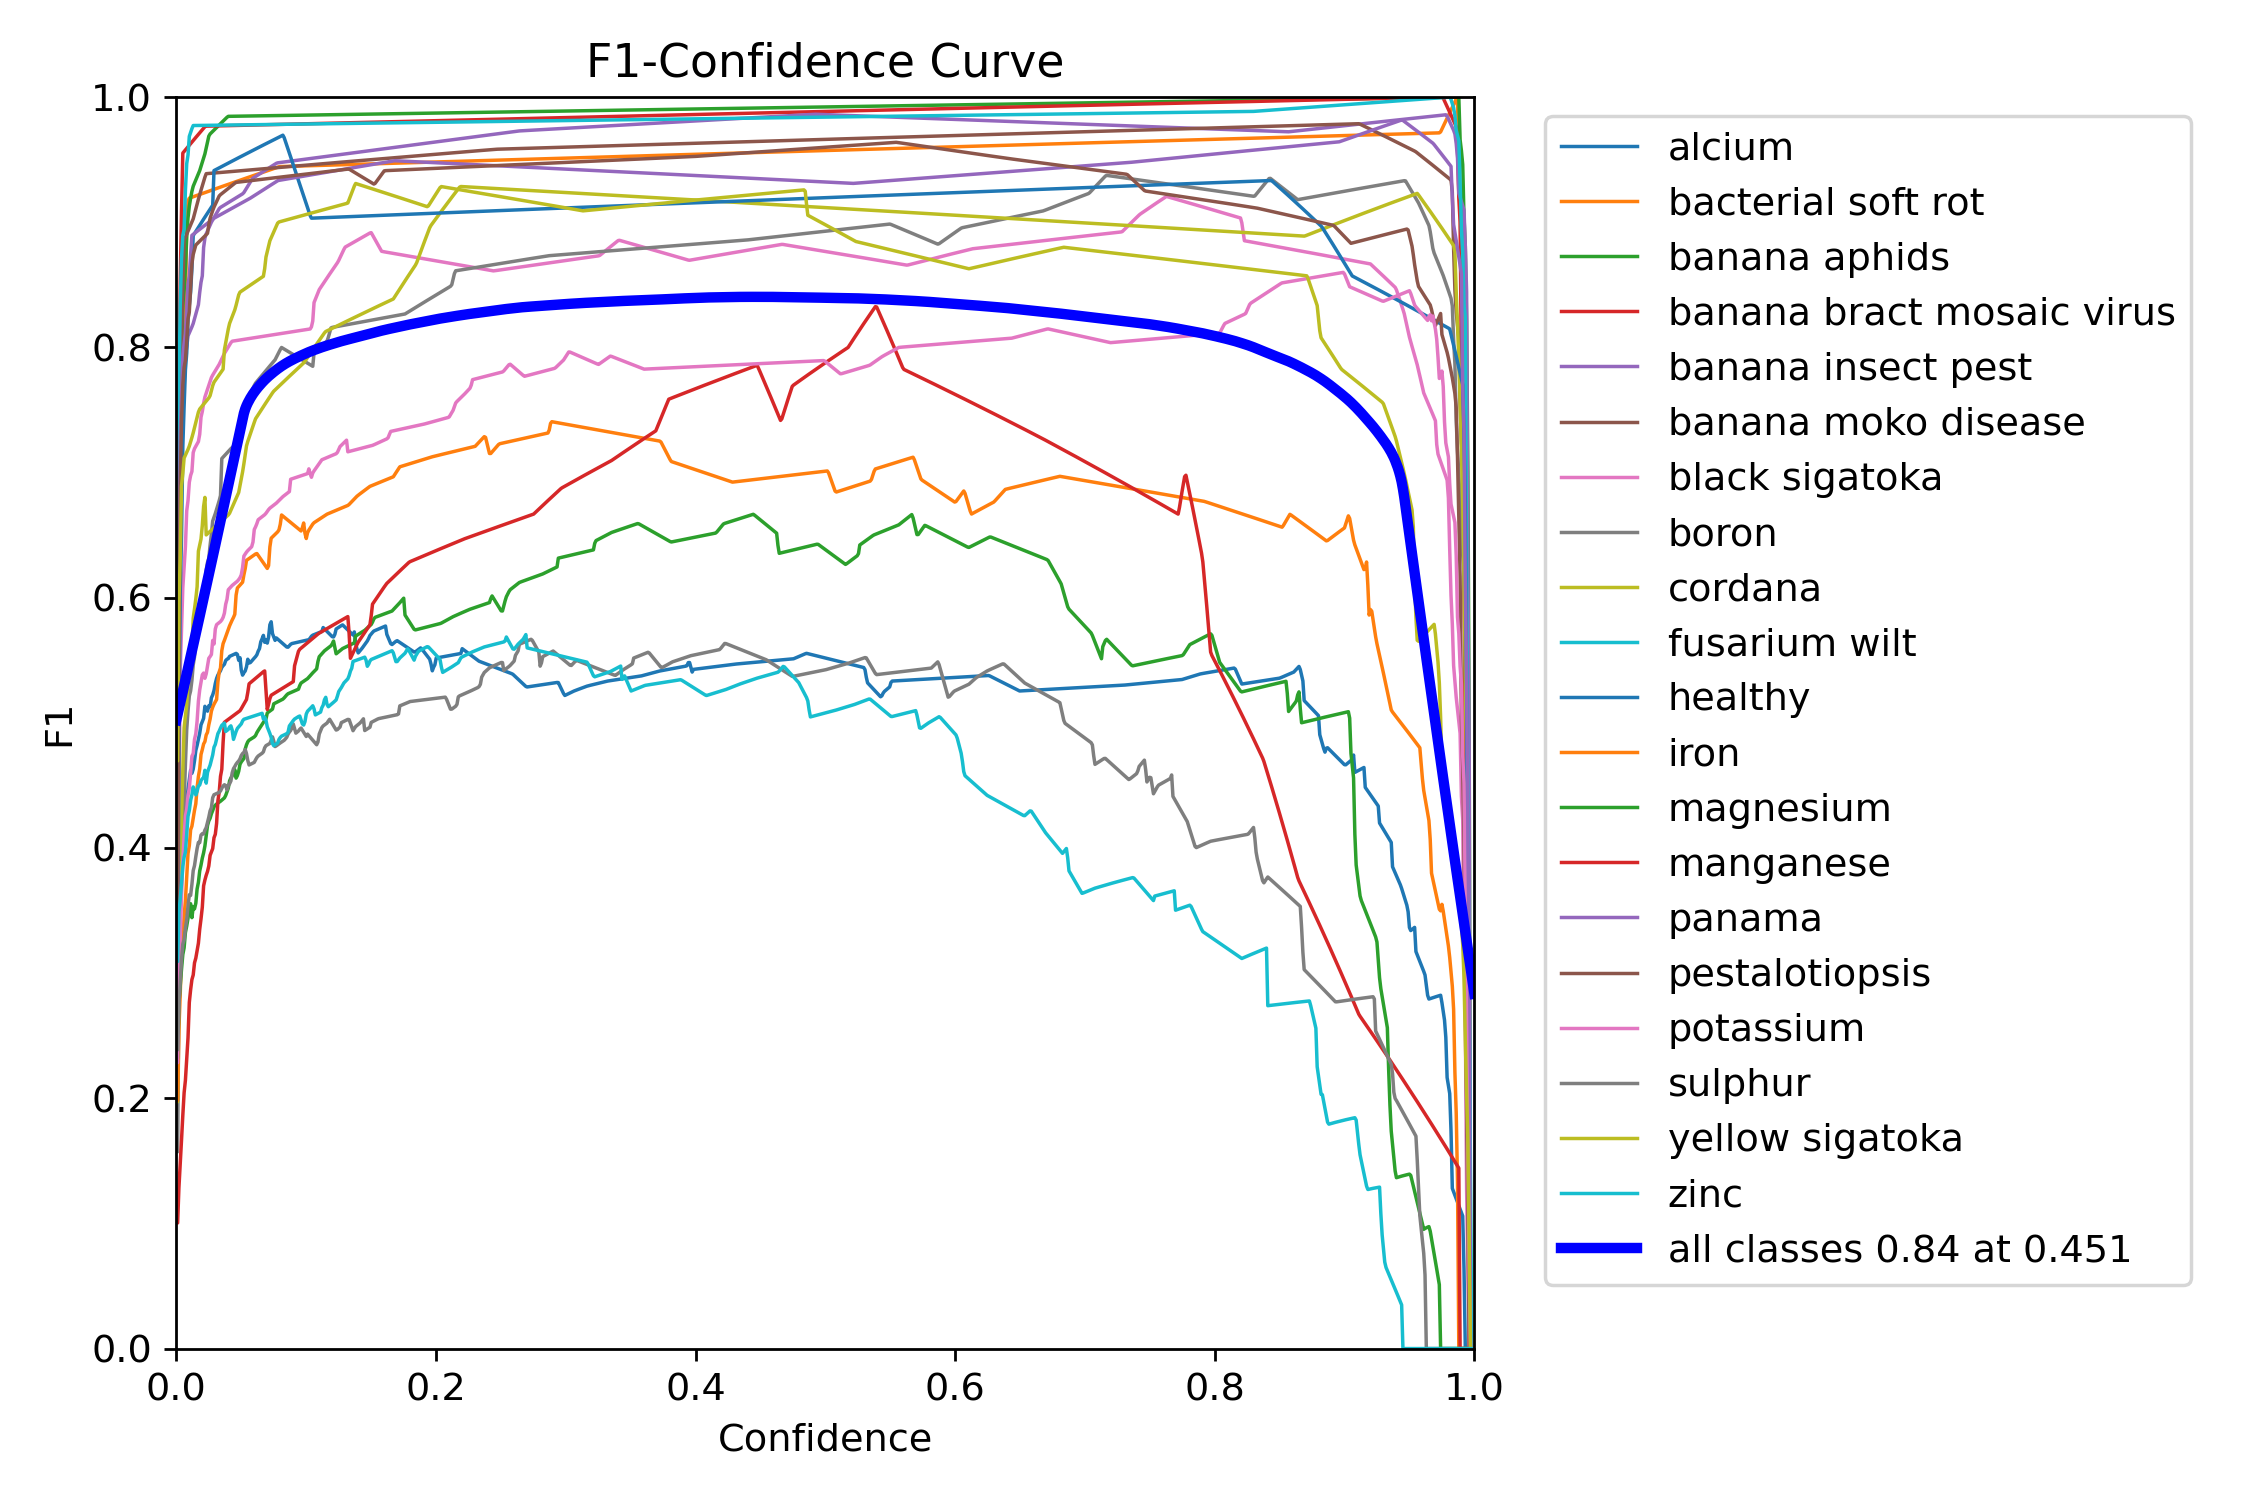

In [29]:
Image(filename=f'/content/drive/MyDrive/Final_Project/Banana/Banana_Results/runs/detect/train2/F1_curve.png', width=600)

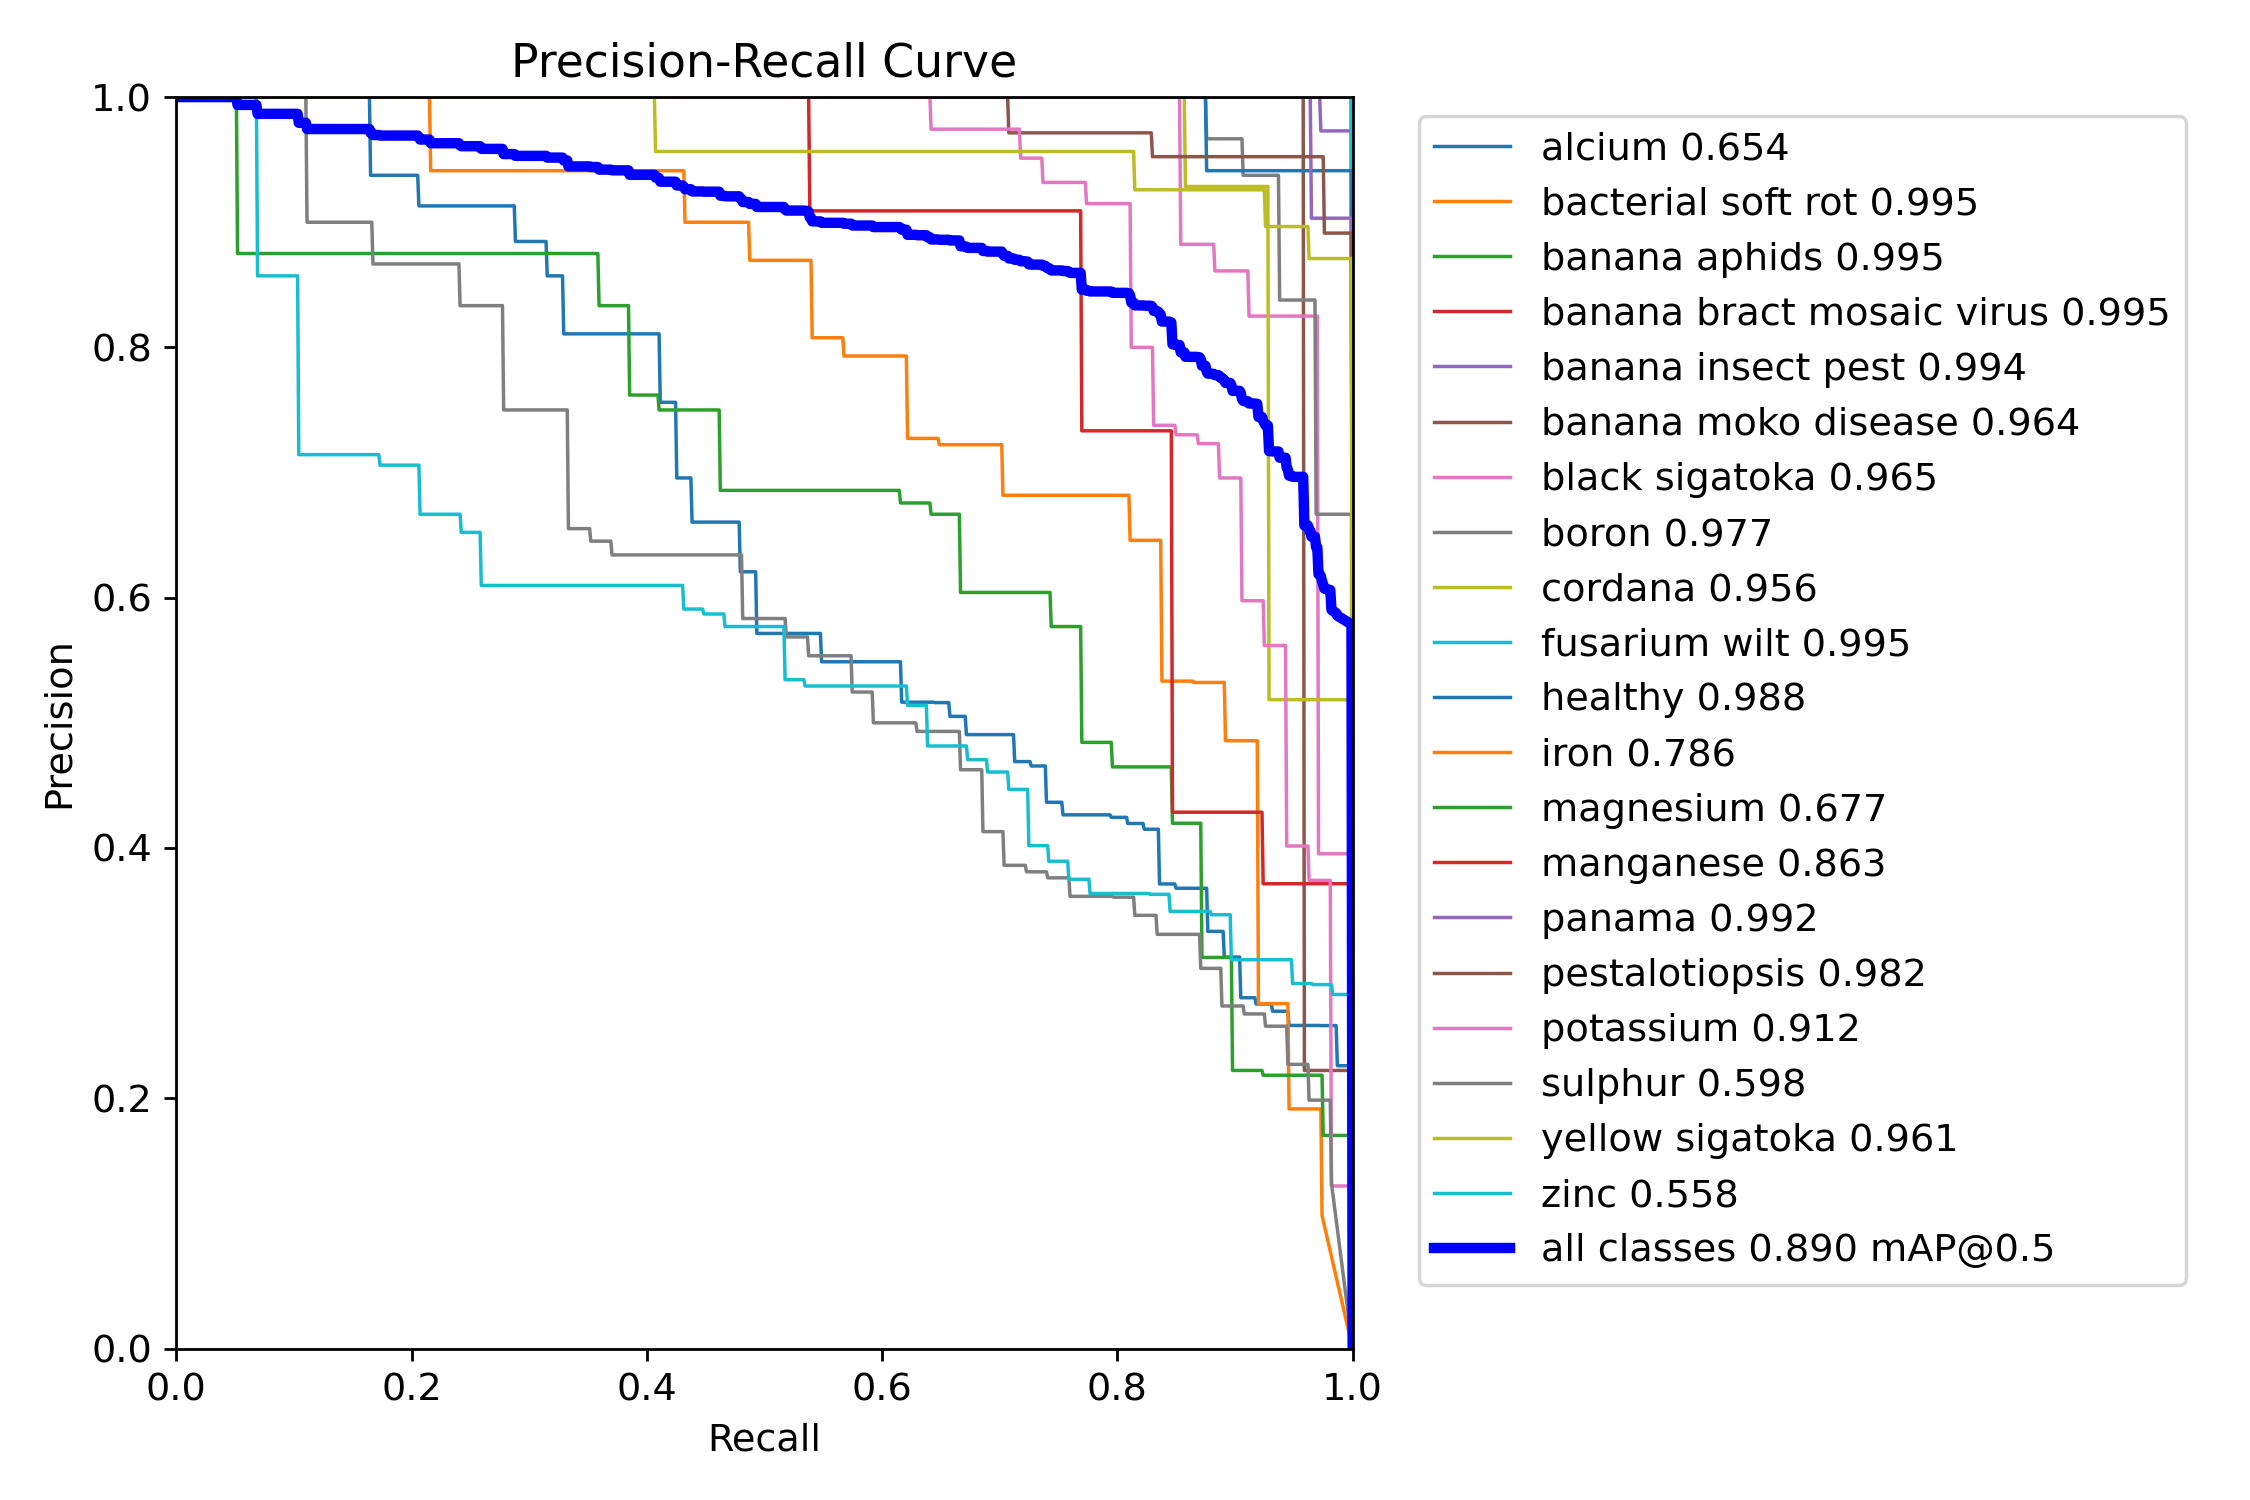

In [30]:
Image(filename=f'/content/drive/MyDrive/Final_Project/Banana/Banana_Results/runs/detect/train2/PR_curve.png', width=600)

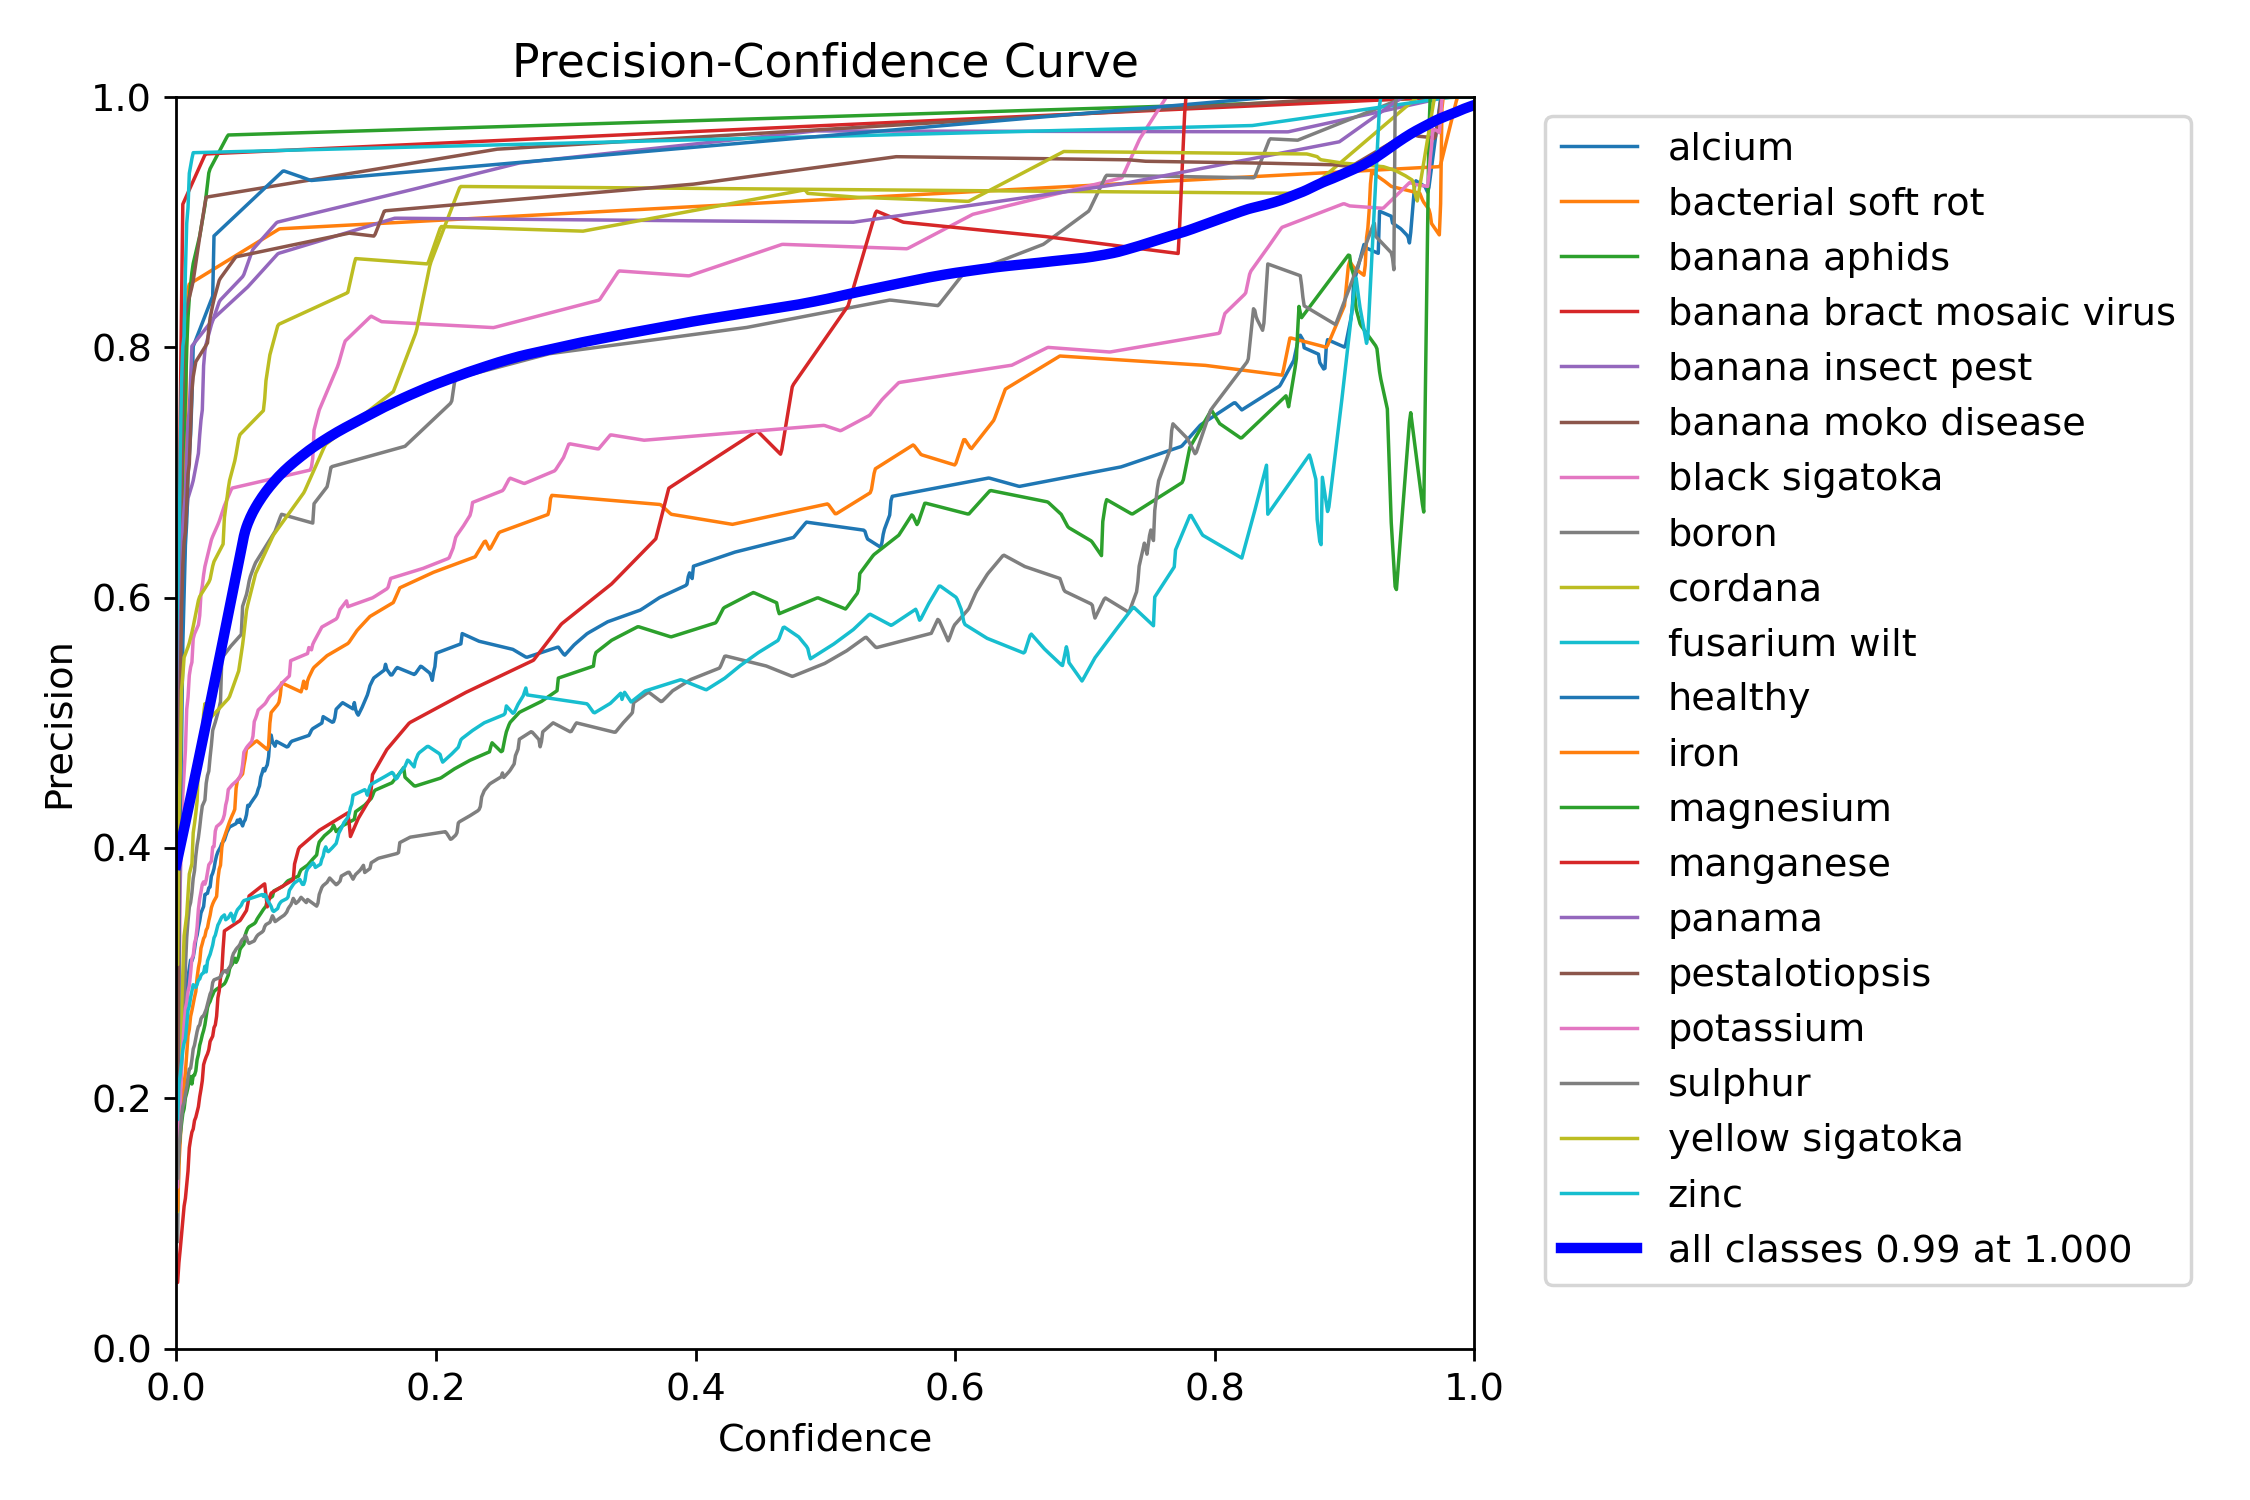

In [31]:
Image(filename=f'/content/drive/MyDrive/Final_Project/Banana/Banana_Results/runs/detect/train2/P_curve.png', width=600)

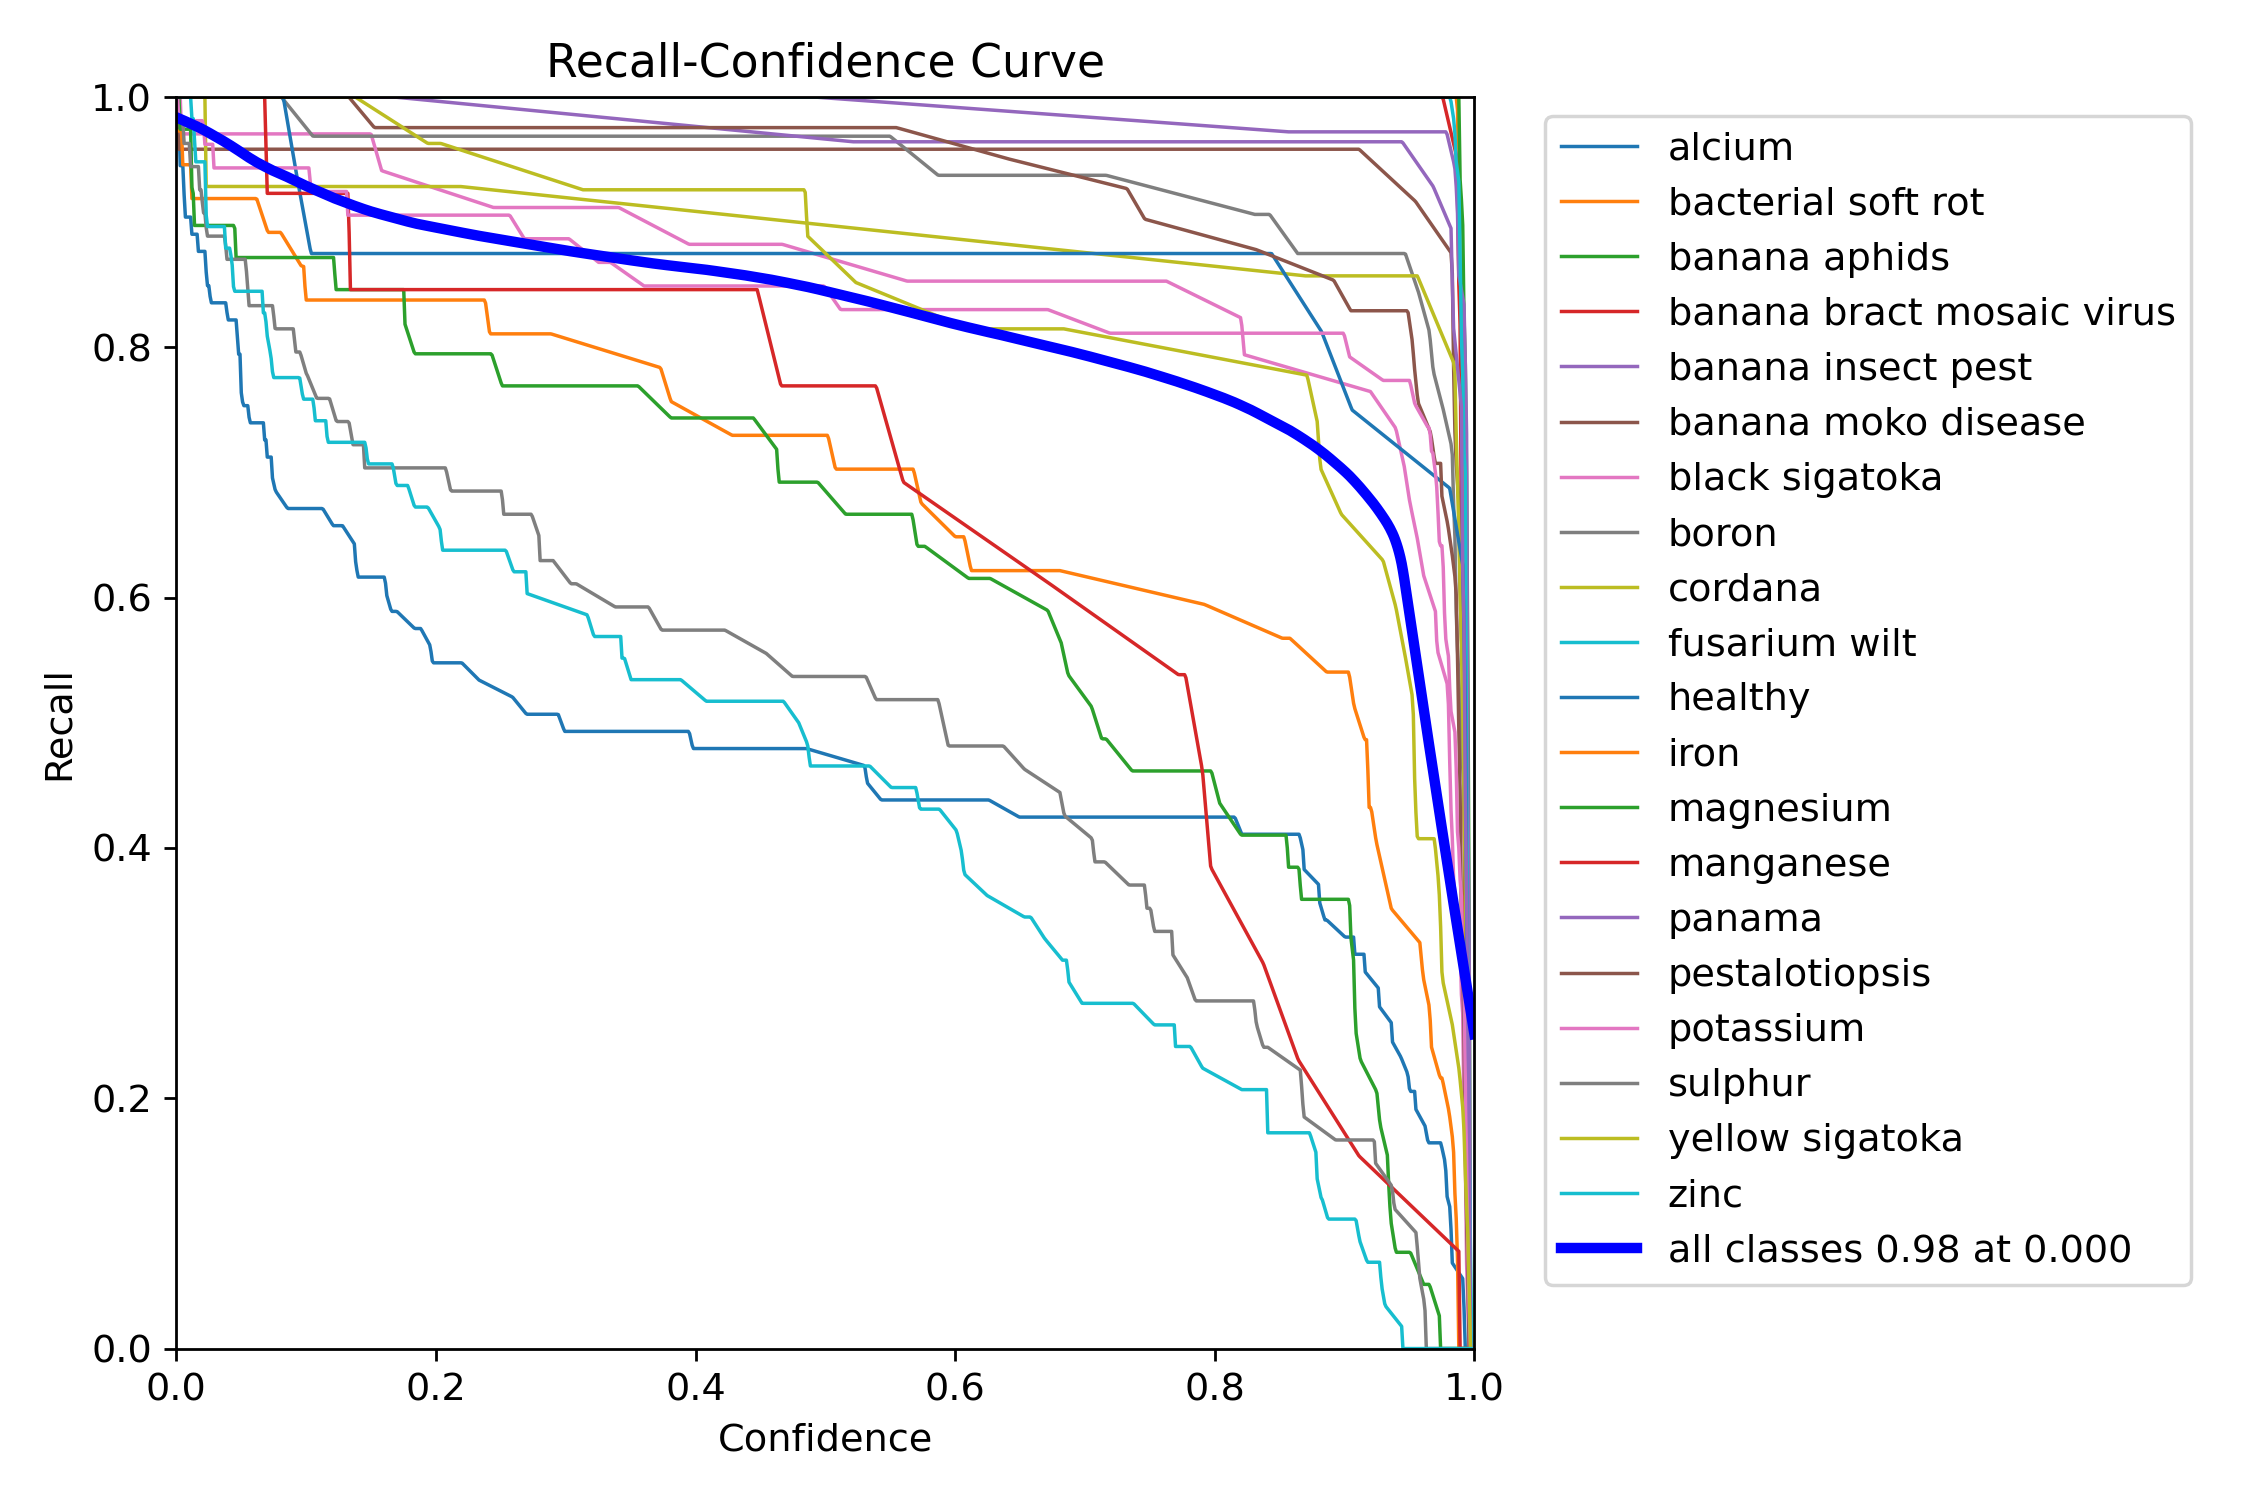

In [32]:
Image(filename=f'/content/drive/MyDrive/Final_Project/Banana/Banana_Results/runs/detect/train2/R_curve.png', width=600)

## Validate Custom Model

In [36]:
!yolo task=detect mode=val model='/content/drive/MyDrive/Final_Project/Banana/Banana_Results/runs/detect/train2/weights/best.pt' data="/content/drive/MyDrive/Final_Project/Banana/data.yaml"


Ultralytics 8.3.111 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
Model summary (fused): 72 layers, 3,009,548 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.8±0.3 ms, read: 20.5±11.5 MB/s, size: 38.8 KB)
val: Scanning /content/drive/MyDrive/Final_Project/Banana/valid/labels.cache... 692 images, 0 backgrounds, 0 corrupt: 100% 692/692 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% 44/44 [00:17<00:00,  2.58it/s]
                   all        692        692      0.829      0.857      0.891       0.89
                alcium         73         73      0.642      0.479      0.654      0.654
    bacterial soft rot         17         17      0.915          1      0.995      0.995
         banana aphids         32         32      0.983          1      0.995      0.995
banana bract mosaic virus         21         21      0.975          1      0.995      0.995
    banana insect pest         36 

## Inference with Custom Model

Running inference on ca_329_jpg.rf.5464c24693762f251bb78eb4682c8742.jpg

image 1/1 /content/drive/MyDrive/Final_Project/Banana/test/images/ca_329_jpg.rf.5464c24693762f251bb78eb4682c8742.jpg: 640x640 1 alcium, 13.9ms
Speed: 2.0ms preprocess, 13.9ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)
Inference complete!


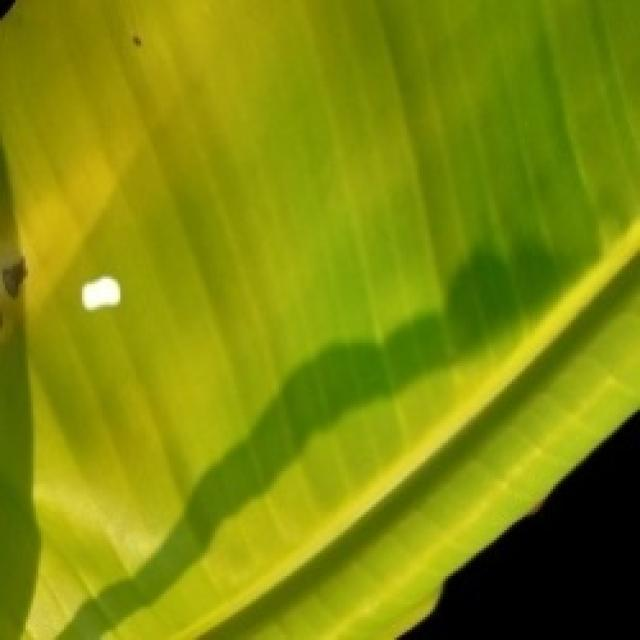

In [ ]:
from ultralytics import YOLO
import os, random
from IPython.display import display
from PIL import Image

# Load the trained YOLOv8 model
model = YOLO("/content/drive/MyDrive/Final_Project/Banana/yolov12/runs/detect/train/weights/best.pt")

# Set the test dataset directory (ensure it's a directory, not a file)
test_set_loc = "/content/drive/MyDrive/Final_Project/Banana/test/images"

# Choose a random test image
random_test_image = random.choice(os.listdir(test_set_loc))
print("Running inference on " + random_test_image)

# Construct the correct path
test_image_path = os.path.join(test_set_loc, random_test_image)

# Run inference on the selected test image
results = model.predict(test_image_path, conf=0.4, iou=0.3)

# Display the results
print("Inference complete!")

# Show the test image
img = Image.open(test_image_path)
display(img)
